<a href="https://colab.research.google.com/github/sharonwambua/SemProject_MLEngine/blob/main/CNN_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Semester Project · Deliverable 2

## Reading Water-Meter Readings from Photographs

This project explores how machine learning can help read an analog water meter from a photograph. The system is designed to find the number display, make sure it is the right way up, and recognise the digits.

**Dataset:** The notebook uses 1,244 water-meter photographs. After checking the data, 1,208 images were suitable for digit reading.

**Goal:** Given a photograph, the system should return the meter reading, for example `00595.825 m³`.

**Learning approach:** This is a supervised learning project because the photographs come with the correct readings and marked display areas. The models learn from these examples and are tested on photographs they have not seen before.

**Main finding:** Random Forest achieved the strongest individual-digit and cross-validation results among the digit-reading models tested. However, SVM achieved a higher test score for complete readings. The results are still too low for automatic billing, so the selected model should be treated as a promising starting point rather than a finished solution.

---

## Project stages

1. **Understand and clean the data:** Check the photographs, readings and marked display areas.
2. **Prepare the photographs:** Find the display, crop it and correct its direction.
3. **Train and compare models:** Test different ways of recognising the digits.
4. **Review the results:** Compare how often the models read individual digits, whole-number readings and complete readings correctly.
5. **Check the full process:** Review how the stages work together and how long they take.

## Models used

- **U-Net:** Finds the display area in the photograph.
- **Orientation CNN:** Checks whether the display is upright or upside down.
- **Random Forest:** Selected as the main digit-reading model based on its strong individual-digit and cross-validation results.
- **Other models:** CNN, SVM, Logistic Regression and other methods are kept in the comparison so their results can be reported fairly.

**Important:** The current test and timing section still use the original CNN reader. Random Forest has been compared as a digit reader, but it has not yet been tested as part of the complete photo-to-reading process. The notebook states this distinction wherever the results are discussed.



In [ ]:
%pip -q install scikit-image seaborn

import os, zipfile, shutil
from pathlib import Path

print('Dependencies installed.')


Dependencies installed.


In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
from pathlib import Path


drive.mount('/content/drive')


DATA_ROOT = Path('/content/drive/MyDrive/water_meter_dataset')

CSV_PATH = DATA_ROOT / 'data.csv'
IMAGE_DIR = DATA_ROOT / 'images'
MASK_DIR = DATA_ROOT / 'masks'

# Check if everything exists
if not CSV_PATH.exists():
    raise FileNotFoundError("data.csv was not found!")

if not IMAGE_DIR.exists():
    raise FileNotFoundError("Images folder was not found!")

if not MASK_DIR.exists():
    raise FileNotFoundError("Masks folder was not found!")

print("Dataset connected successfully!")
print("Images:", len(list(IMAGE_DIR.iterdir())))
print("Masks:", len(list(MASK_DIR.iterdir())))


Mounted at /content/drive
Dataset connected successfully!
Images: 1244
Masks: 1244


# Part 1 · Machine Learning Approach

## What does the system need to do?

The system receives a photograph of a water meter and should return the number shown on its display. The dataset includes the correct reading and a marked area showing where the display is located.

Because the correct answers are provided with the photographs, the project uses **supervised learning**. In simple terms, the models learn from examples that already have answers.

## Finding the display

We use **U-Net** to find the part of the photograph that contains the meter reading. The system then crops that area and straightens it so the digits are easier to read.

## Checking the direction

Some photographs may show the display upside down. A small **CNN** checks whether the display is upright or upside down so it can be corrected before the digits are read.

## Recognising the digits

The notebook compares several models for reading the digits, including CNN, Random Forest, SVM and other traditional machine-learning methods.

**Random Forest is selected as the preferred digit-reading model for the next version of the system** because it achieved the highest individual-digit accuracy and the strongest cross-validation results in this experiment. SVM is also retained in the discussion because it achieved a higher test score for complete readings.

The models are compared using the same prepared images and evaluation measures. This helps make the comparison fair and avoids choosing a model based on only one result.

## Why this is supervised learning

Each training photograph has a known reading. The model compares its predictions with those correct answers and learns from the differences. It can then make predictions for new photographs.


In [ ]:
import os, re, ast, json, glob, math, time, random, gc, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from skimage.feature import hog
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k): return x
try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False})

# configuration
SEED = 42
DATA_ROOT = globals().get('DATA_ROOT', None)
FAST_DEV = False
SEG_SIZE = 256
CROP_H, CROP_W = 64, 256
N_DIGITS = 8
CROP_CLAHE = True
NEAR_DUP_BITS = 4
POS_LABELS = ['10^4', '10^3', '10^2', '10^1', '10^0', '10^-1', '10^-2', '10^-3']

random.seed(SEED); np.random.seed(SEED)

def find_dataset_root():
    cands = [Path(p).parent for p in glob.glob('/content/**/data.csv', recursive=True)]
    cands += [Path(p).parent for p in glob.glob('/kaggle/input/**/data.csv', recursive=True)]
    cands += [Path(p) for p in ['./WaterMeters', '../WaterMeters', '/content/WaterMeters']]
    for r in cands:
        if (r / 'data.csv').exists() and (r / 'images').is_dir() and (r / 'masks').is_dir():
            return r
    return None

if DATA_ROOT is None:
    DATA_ROOT = find_dataset_root()
WORK_DIR = Path('/content/outputs') if Path('/content').exists() else (Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('./outputs'))
WORK_DIR.mkdir(parents=True, exist_ok=True)
USE_SYNTHETIC = DATA_ROOT is None
if USE_SYNTHETIC and Path('/content').exists():
    raise FileNotFoundError('Real dataset not found in Google Colab. Run the dataset upload cell and verify data.csv, images/, and masks/ before continuing.')
print('Dataset root :', DATA_ROOT if not USE_SYNTHETIC else 'NOT FOUND -> synthetic demo data will be generated')

Dataset root : /content/drive/MyDrive/water_meter_dataset


# Part 2 · Data Cleaning

Before training, the dataset is checked to make sure the photographs, readings and display markings are usable.

The checks look for:
- Repeated photographs.
- Missing photographs or display masks.
- Missing or invalid readings.
- Readings that do not match their filenames.
- Incorrect or unclear display markings.

The notebook also checks whether the photographs and masks can be opened. Records that fail the checks are removed so they do not affect training.

The cleaning results are shown in the tables produced by the cells below.


In [ ]:
def parse_polygon(loc):
    try:
        d = ast.literal_eval(loc) if isinstance(loc, str) else loc
        pts = np.array([[p['x'], p['y']] for p in d['data']], dtype=np.float64)
        return pts if pts.ndim == 2 and pts.shape[1] == 2 else None
    except Exception:
        return None

def poly_area(p):
    x, y = p[:, 0], p[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))

def name_value(n):
    m = re.search(r'value_(\d+)_(\d+)', str(n))
    return float(f'{m.group(1)}.{m.group(2)}') if m else np.nan

def find_mask(name):
    stem = Path(name).stem
    for cand in [name, stem + '.jpg', stem + '.png']:
        if (MASK_DIR / cand).exists():
            return str(MASK_DIR / cand)
    return None

def value_to_digits(v):
    n = int(round(float(v) * 1000)); s = f'{n:0{N_DIGITS}d}'
    return np.array([int(c) for c in s], dtype=np.int64)

def digits_to_value(D):
    D = np.asarray(D, dtype=np.int64); ok = (D >= 0).all(-1)
    v = (np.clip(D, 0, 9) * (10 ** np.arange(N_DIGITS - 1, -1, -1))).sum(-1) / 1000.0
    return np.where(ok, v, np.nan)

def fmt_reading(d):
    if (np.asarray(d) < 0).any(): return 'FAIL'
    s = ''.join(str(int(x)) for x in d); return s[:5] + '.' + s[5:]

def window_geometry(mask_bin, min_area=30):
    n, lab, st, _ = cv2.connectedComponentsWithStats(mask_bin.astype(np.uint8), connectivity=8)
    if n <= 1: return None
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    if st[k, cv2.CC_STAT_AREA] < min_area: return None
    pts = cv2.findNonZero((lab == k).astype(np.uint8))
    hull = cv2.convexHull(pts)
    rect = cv2.minAreaRect(hull)
    box = cv2.boxPoints(rect)
    e1, e2 = box[1] - box[0], box[2] - box[1]
    n1, n2 = np.linalg.norm(e1), np.linalg.norm(e2)
    d, L, S = (e1 / n1, n1, n2) if n1 >= n2 else (e2 / n2, n2, n1)
    if abs(d[0]) >= abs(d[1]):
        if d[0] < 0: d = -d
    elif d[1] < 0:
        d = -d
    return dict(center=(float(rect[0][0]), float(rect[0][1])), d=d.astype(np.float32), L=float(L), S=float(max(S, 1.0)),
                angle=float(np.degrees(np.arctan2(d[1], d[0]))))

_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 8))
def apply_clahe(rgb):
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB); lab[..., 0] = _clahe.apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def warp_window(img_rgb, geo, out_hw=(CROP_H, CROP_W), pad_l=0.04, pad_s=0.18, clahe=CROP_CLAHE):
    H, W = out_hw
    c = np.array(geo['center'], np.float32); d = np.array(geo['d'], np.float32); nrm = np.array([-d[1], d[0]], np.float32)
    hl, hs = geo['L'] * (1 + 2 * pad_l) / 2, geo['S'] * (1 + 2 * pad_s) / 2
    src = np.stack([c - d * hl - nrm * hs, c + d * hl - nrm * hs, c + d * hl + nrm * hs, c - d * hl + nrm * hs]).astype(np.float32)
    k = 2
    dst = np.array([[0, 0], [W * k - 1, 0], [W * k - 1, H * k - 1], [0, H * k - 1]], np.float32)
    big = cv2.warpPerspective(img_rgb, cv2.getPerspectiveTransform(src, dst), (W * k, H * k), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    out = cv2.resize(big, (W, H), interpolation=cv2.INTER_AREA)
    return apply_clahe(out) if clahe else out

def dhash_bits(gray):
    s = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA)
    return (s[:, 1:] > s[:, :-1]).flatten().astype(np.int8)

cleaning_log = []
def log_step(step, check, flagged, action, remaining):
    cleaning_log.append(dict(step=step, check=check, flagged=int(flagged), action=action, rows_remaining=int(remaining)))
    print(f'[{step}] {check}: flagged {int(flagged)} -> {action}; {int(remaining)} rows remain')

In [ ]:
import pandas as pd

# Reads the raw dataset first
raw = pd.read_csv(CSV_PATH)
df = raw.copy()

duplicates = df.duplicated(subset=['photo_name'], keep='first')
df = df.loc[~duplicates].copy()

log_step(
    'C1',
    'Repeated photographs',
    duplicates.sum(),
    'Removed extra copies',
    len(df)
)

# Checks that every photograph has a matching image and mask
df['img_path'] = df['photo_name'].map(lambda n: str(IMAGE_DIR / n))
df['mask_path'] = df['photo_name'].map(find_mask)

missing = ~df['img_path'].map(os.path.exists) | df['mask_path'].isna()
df = df.loc[~missing].copy()

log_step(
    'C2',
    'Missing photographs or masks',
    missing.sum(),
    'Removed incomplete records',
    len(df)
)

# Checks if the water meter readings are valid
df['value'] = pd.to_numeric(df['value'], errors='coerce')

bad_val = (
    df['value'].isna()
    | (df['value'] < 0)
    | (df['value'] >= 10 ** (N_DIGITS - 3))
)

df = df.loc[~bad_val].copy()

log_step(
    'C3a',
    'Invalid water readings',
    bad_val.sum(),
    'Removed invalid readings',
    len(df)
)

# Checks if the reading matches the photograph's filename
df['value_from_name'] = df['photo_name'].map(name_value)

mism = (df['value'] - df['value_from_name']).abs() > 1e-6
df = df.loc[~mism].copy()

log_step(
    'C3b',
    'Readings that do not match their filenames',
    mism.sum(),
    'Removed records with conflicting readings',
    len(df)
)

# Checks if the marked reading window is valid
df['poly'] = df['location'].map(parse_polygon)

def poly_ok(p):
    return (
        p is not None
        and len(p) >= 3
        and np.isfinite(p).all()
        and poly_area(p) > 1e-4
        and p.min() > -0.02
        and p.max() < 1.02
    )

bad_poly = ~df['poly'].map(poly_ok)

df = df.loc[~bad_poly].copy()
df['poly'] = df['poly'].map(lambda p: np.clip(p, 0, 1))
df = df.reset_index(drop=True)

log_step(
    'C4',
    'Incorrect or unclear reading-window markings',
    bad_poly.sum(),
    'Removed invalid markings',
    len(df)
)

# Shows the cleaning results
cleaning_summary = pd.DataFrame(cleaning_log)

display(cleaning_summary)

[C1] Repeated photographs: flagged 0 -> Removed extra copies; 1244 rows remain
[C2] Missing photographs or masks: flagged 0 -> Removed incomplete records; 1244 rows remain
[C3a] Invalid water readings: flagged 0 -> Removed invalid readings; 1244 rows remain
[C3b] Readings that do not match their filenames: flagged 0 -> Removed records with conflicting readings; 1244 rows remain
[C4] Incorrect or unclear reading-window markings: flagged 0 -> Removed invalid markings; 1244 rows remain


,step,check,flagged,action,rows_remaining
0,C1,Repeated photographs,0,Removed extra copies,1244
1,C2,Missing photographs or masks,0,Removed incomplete records,1244
2,C3a,Invalid water readings,0,Removed invalid readings,1244
3,C3b,Readings that do not match their filenames,0,Removed records with conflicting readings,1244
4,C4,Incorrect or unclear reading-window markings,0,Removed invalid markings,1244


In [ ]:
def read_aligned(img_path, mask_path):
    m = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE); im = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if im is None or m is None: return None, None, 'unreadable'
    fix = 'none'
    if im.shape[:2] != m.shape[:2]:
        im2 = cv2.imread(img_path, cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION)
        if im2 is not None and im2.shape[:2] == m.shape[:2]: im, fix = im2, 'ignore_exif'
        else: return None, None, 'shape_mismatch'
    return im, m, fix

def extract_record(row):
    im, m, fix = read_aligned(row['img_path'], row['mask_path'])
    if im is None: return None, fix
    H, W = im.shape[:2]
    binm = (m > 127).astype(np.uint8)
    area_frac = float(binm.mean())
    if area_frac < 2e-4: return None, 'empty_mask'
    pm = np.zeros((H, W), np.uint8)
    cv2.fillPoly(pm, [np.round(row['poly'] * [W - 1, H - 1]).astype(np.int32)], 1)
    iou = float((pm & binm).sum() / max((pm | binm).sum(), 1))
    geo = window_geometry(binm)
    if geo is None: return None, 'no_window'
    rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
    img256 = cv2.resize(rgb, (SEG_SIZE, SEG_SIZE), interpolation=cv2.INTER_AREA)
    m256 = (cv2.resize(binm * 255, (SEG_SIZE, SEG_SIZE), interpolation=cv2.INTER_AREA) > 127).astype(np.uint8)
    g = cv2.cvtColor(img256, cv2.COLOR_RGB2GRAY)
    ang = geo['angle']; a = abs(ang)
    orient = 'horizontal' if a <= 30 else ('vertical' if 60 <= a <= 120 else 'diagonal')
    meta = dict(H=H, W=W, exif_fix=fix, area_frac=area_frac, poly_mask_iou=iou, L=geo['L'], S=geo['S'], aspect=geo['L'] / geo['S'],
                angle=ang, orient=orient, cx=geo['center'][0] / W, cy=geo['center'][1] / H, n_poly_pts=len(row['poly']),
                brightness=float(g.mean()), contrast=float(g.std()), sharpness=float(cv2.Laplacian(g, cv2.CV_64F).var()))
    return dict(meta=meta, img256=img256, m256=m256, crop=warp_window(rgb, geo), bits=dhash_bits(g)), 'ok'

recs, fail_reasons = [], {}
for i, row in tqdm(list(df.iterrows()), desc='reading photos'):
    r, why = extract_record(row)
    if r is None: fail_reasons[why] = fail_reasons.get(why, 0) + 1; recs.append(None)
    else: recs.append(r)
ok = np.array([r is not None for r in recs])
for why, c in fail_reasons.items():
    log_step('C5', f'pixel check failed: {why}', c, 'drop', len(df) - sum(fail_reasons.values()))
df = df.loc[ok].reset_index(drop=True); recs = [r for r in recs if r is not None]
ds = pd.concat([df[['photo_name', 'value', 'img_path', 'mask_path']].reset_index(drop=True), pd.DataFrame([r['meta'] for r in recs])], axis=1)
IMG256 = np.stack([r['img256'] for r in recs]); MASK256 = np.stack([r['m256'] for r in recs])
CROPS_RAW = np.stack([r['crop'] for r in recs]); BITS = np.stack([r['bits'] for r in recs]).astype(np.float32)
del recs; gc.collect()

def apply_keep(keep):
    global ds, IMG256, MASK256, CROPS_RAW, BITS
    keep = np.asarray(keep, bool)
    ds = ds.loc[keep].reset_index(drop=True); IMG256, MASK256, CROPS_RAW, BITS = IMG256[keep], MASK256[keep], CROPS_RAW[keep], BITS[keep]
bad_iou = (ds['poly_mask_iou'] < 0.5).values
if bad_iou.mean() < 0.10:
    apply_keep(~bad_iou); log_step('C5b', 'polygon-vs-mask IoU < 0.5 (annotation disagrees with itself)', bad_iou.sum(), 'drop', len(ds))
else:
    print(f'WARNING: {bad_iou.mean():.0%} of images have polygon/mask IoU<0.5 -> systematic; KEEPING them (masks are the primary label).')
    log_step('C5b', 'polygon-vs-mask IoU < 0.5 (systematic)', bad_iou.sum(), 'keep + warn', len(ds))
print('EXIF alignment fixes applied:', int((ds['exif_fix'] != 'none').sum()))

reading photos:   0%|          | 0/1244 [00:00<?, ?it/s]

[C5b] polygon-vs-mask IoU < 0.5 (annotation disagrees with itself): flagged 0 -> drop; 1244 rows remain
EXIF alignment fixes applied: 0


In [ ]:

# Inspectsd the image and mask data before training U-Net

print("IMAGE AND MASK DIAGNOSTICS")
print("-" * 40)

print("Number of images:", len(IMG256))
print("Number of masks:", len(MASK256))

print("\nImage shape:", IMG256.shape)
print("Mask shape:", MASK256.shape)

print("\nImage data type:", IMG256.dtype)
print("Mask data type:", MASK256.dtype)

print("\nImage pixel range:",
      IMG256.min(), "to", IMG256.max())

print("\nMask pixel range:",
      MASK256.min(), "to", MASK256.max())

print("\nMask unique values (first 20):",
      np.unique(MASK256)[:20])

# Checks the percentage of white pixels in each mask
print("\nFOREGROUND PIXEL PERCENTAGES")

for i in range(len(MASK256)):
    mask = MASK256[i]
    percentage = np.mean(mask > 0) * 100

    print(f"Image {i}: {percentage:.2f}%")


IMAGE AND MASK DIAGNOSTICS
----------------------------------------
Number of images: 1244
Number of masks: 1244

Image shape: (1244, 256, 256, 3)
Mask shape: (1244, 256, 256)

Image data type: uint8
Mask data type: uint8

Image pixel range: 0 to 255

Mask pixel range: 0 to 1

Mask unique values (first 20): [0 1]

FOREGROUND PIXEL PERCENTAGES
Image 0: 0.74%
Image 1: 1.74%
Image 2: 6.03%
Image 3: 3.97%
Image 4: 1.12%
Image 5: 3.16%
Image 6: 2.58%
Image 7: 1.61%
Image 8: 3.29%
Image 9: 1.24%
Image 10: 3.93%
Image 11: 0.87%
Image 12: 3.63%
Image 13: 1.37%
Image 14: 1.45%
Image 15: 2.17%
Image 16: 2.08%
Image 17: 4.06%
Image 18: 4.90%
Image 19: 2.69%
Image 20: 1.12%
Image 21: 2.10%
Image 22: 0.70%
Image 23: 3.39%
Image 24: 2.75%
Image 25: 1.88%
Image 26: 3.25%
Image 27: 2.26%
Image 28: 3.49%
Image 29: 5.55%
Image 30: 1.30%
Image 31: 2.22%
Image 32: 1.26%
Image 33: 3.01%
Image 34: 2.81%
Image 35: 1.25%
Image 36: 1.62%
Image 37: 1.00%
Image 38: 2.25%
Image 39: 2.40%
Image 40: 1.27%
Image 41:

In [ ]:
# C6 : exact/duplicate photos
def hamming_matrix(bits):
    return 64 - (bits @ bits.T + (1 - bits) @ (1 - bits).T)

dist = hamming_matrix(BITS); np.fill_diagonal(dist, 99)
same_val = np.abs(ds['value'].values[:, None] - ds['value'].values[None, :]) < 1e-9
exact_pairs = np.argwhere(np.triu((dist == 0) & same_val, 1))
drop_dups = np.zeros(len(ds), bool); drop_dups[exact_pairs[:, 1]] = True
apply_keep(~drop_dups); log_step('C6a', 'exact duplicate photos (same hash and same value)', drop_dups.sum(), 'drop later copy', len(ds))

dist = hamming_matrix(BITS); np.fill_diagonal(dist, 99)
max_ok = max(6, int(0.01 * len(ds)))
for thr_bits in range(NEAR_DUP_BITS, -1, -1):
    n_groups, grp = connected_components(csr_matrix(dist <= thr_bits), directed=False)
    if np.bincount(grp).max() <= max_ok: break
ds['group'] = grp
sizes = np.bincount(grp)
n_in_multi = int((sizes[grp] > 1).sum())
print(f'near-duplicate threshold used: {thr_bits}/64 bits (start {NEAR_DUP_BITS}); largest group = {sizes.max()}, groups with >1 photo = {(sizes > 1).sum()}')
log_step('C6b', f'near-duplicate photos (dHash distance <= {thr_bits}/64, group size <= {max_ok})', n_in_multi, 'KEEP, give shared group id so splits never separate them', len(ds))

# C7 : label ambiguity
ds['value_milli'] = np.round(ds['value'].values * 1000).astype(np.int64)
ds['int_only'] = (ds['value_milli'] % 1000) == 0
ds['reader_ok'] = ~ds['int_only']
DIG = np.stack([value_to_digits(v) for v in ds['value']])
log_step('C7', 'reading has zero decimal part (likely 5-wheel meter: litre digits not visible)', ds['int_only'].sum(),
         'keep for segmentation, exclude from digit reading', int(ds['reader_ok'].sum()))

cleaning_summary = pd.DataFrame(cleaning_log)
display(cleaning_summary)
print(f'\nFINAL: {len(ds)} photos for window segmentation | {int(ds.reader_ok.sum())} for digit reading | {ds.group.nunique()} duplicate-groups')
ds.drop(columns=['img_path', 'mask_path']).to_csv(WORK_DIR / 'clean_dataset.csv', index=False)
cleaning_summary.to_csv(WORK_DIR / 'cleaning_log.csv', index=False)

[C6a] exact duplicate photos (same hash and same value): flagged 0 -> drop later copy; 1244 rows remain
near-duplicate threshold used: 4/64 bits (start 4); largest group = 2, groups with >1 photo = 2
[C6b] near-duplicate photos (dHash distance <= 4/64, group size <= 12): flagged 4 -> KEEP, give shared group id so splits never separate them; 1244 rows remain
[C7] reading has zero decimal part (likely 5-wheel meter: litre digits not visible): flagged 36 -> keep for segmentation, exclude from digit reading; 1208 rows remain


,step,check,flagged,action,rows_remaining
0,C1,Repeated photographs,0,Removed extra copies,1244
1,C2,Missing photographs or masks,0,Removed incomplete records,1244
2,C3a,Invalid water readings,0,Removed invalid readings,1244
3,C3b,Readings that do not match their filenames,0,Removed records with conflicting readings,1244
4,C4,Incorrect or unclear reading-window markings,0,Removed invalid markings,1244
5,C5b,polygon-vs-mask IoU < 0.5 (annotation disagree...,0,drop,1244
6,C6a,exact duplicate photos (same hash and same value),0,drop later copy,1244
7,C6b,"near-duplicate photos (dHash distance <= 4/64,...",4,"KEEP, give shared group id so splits never sep...",1244
8,C7,reading has zero decimal part (likely 5-wheel ...,36,"keep for segmentation, exclude from digit reading",1208



FINAL: 1244 photos for window segmentation | 1208 for digit reading | 1242 duplicate-groups


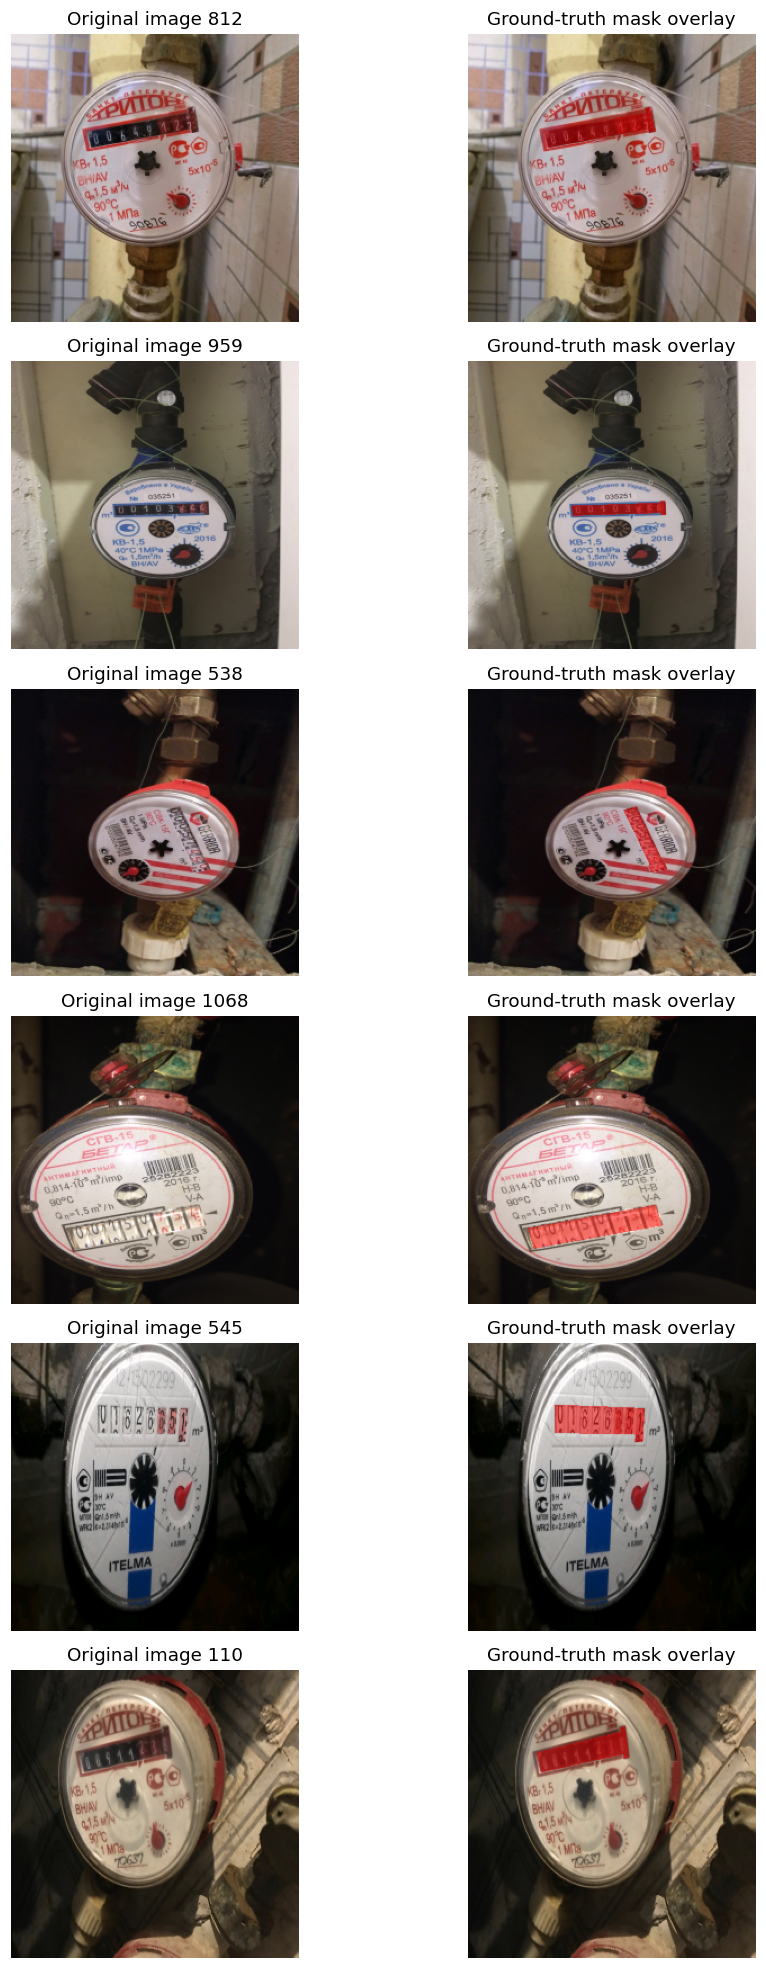

In [ ]:

# Checks whether each ground-truth mask matches its photograph

import matplotlib.pyplot as plt
import numpy as np

n_show = min(6, len(IMG256))
indices = np.random.default_rng(42).choice(
    len(IMG256), size=n_show, replace=False
)

fig, axes = plt.subplots(n_show, 2, figsize=(10, 3 * n_show))

for row, i in enumerate(indices):
    image = IMG256[i].copy()
    mask = MASK256[i].astype(bool)

    # Original photograph
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Original image {i}")
    axes[row, 0].axis("off")

    # Mask drawn over the photograph
    overlay = image.copy()
    overlay[mask] = (
        0.5 * overlay[mask] + 0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)

    axes[row, 1].imshow(overlay)
    axes[row, 1].set_title("Ground-truth mask overlay")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()


## Exploring the Dataset

After cleaning, we examine the photographs to understand what the system will need to handle.

The charts and examples show differences in photograph size, display position, angle, lighting and image quality. These differences matter because the system should be able to find and read displays in photographs taken under different conditions.

The examples also help us check that the display markings and prepared crops match the actual photographs.


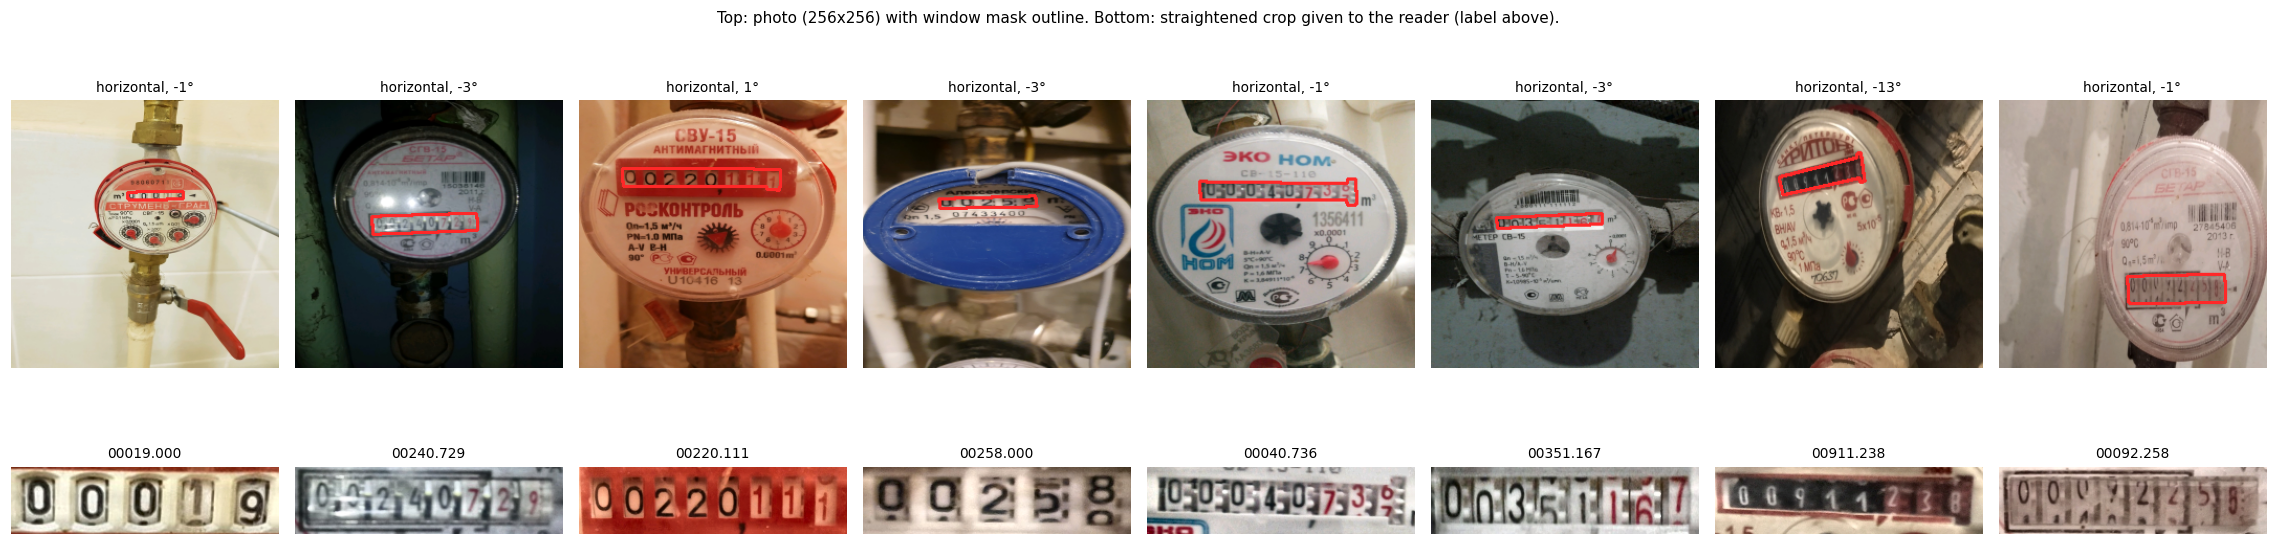

In [ ]:
rng = np.random.default_rng(SEED)
pick = rng.choice(len(ds), size=min(8, len(ds)), replace=False)
fig, axes = plt.subplots(2, len(pick), figsize=(2.6 * len(pick), 6.2))
axes = np.atleast_2d(axes)
for j, i in enumerate(pick):
    im = IMG256[i].copy()
    cnts = cv2.findContours(MASK256[i], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[-2]
    cv2.drawContours(im, cnts, -1, (255, 40, 40), 2)
    axes[0, j].imshow(im); axes[0, j].set_title(f"{ds.orient[i]}, {ds.angle[i]:.0f}°", fontsize=9); axes[0, j].axis('off')
    axes[1, j].imshow(CROPS_RAW[i]); axes[1, j].set_title(fmt_reading(DIG[i]), fontsize=9); axes[1, j].axis('off')
plt.suptitle('Top: photo (256x256) with window mask outline. Bottom: straightened crop given to the reader (label above).', y=1.0, fontsize=10)
plt.tight_layout(); plt.show()

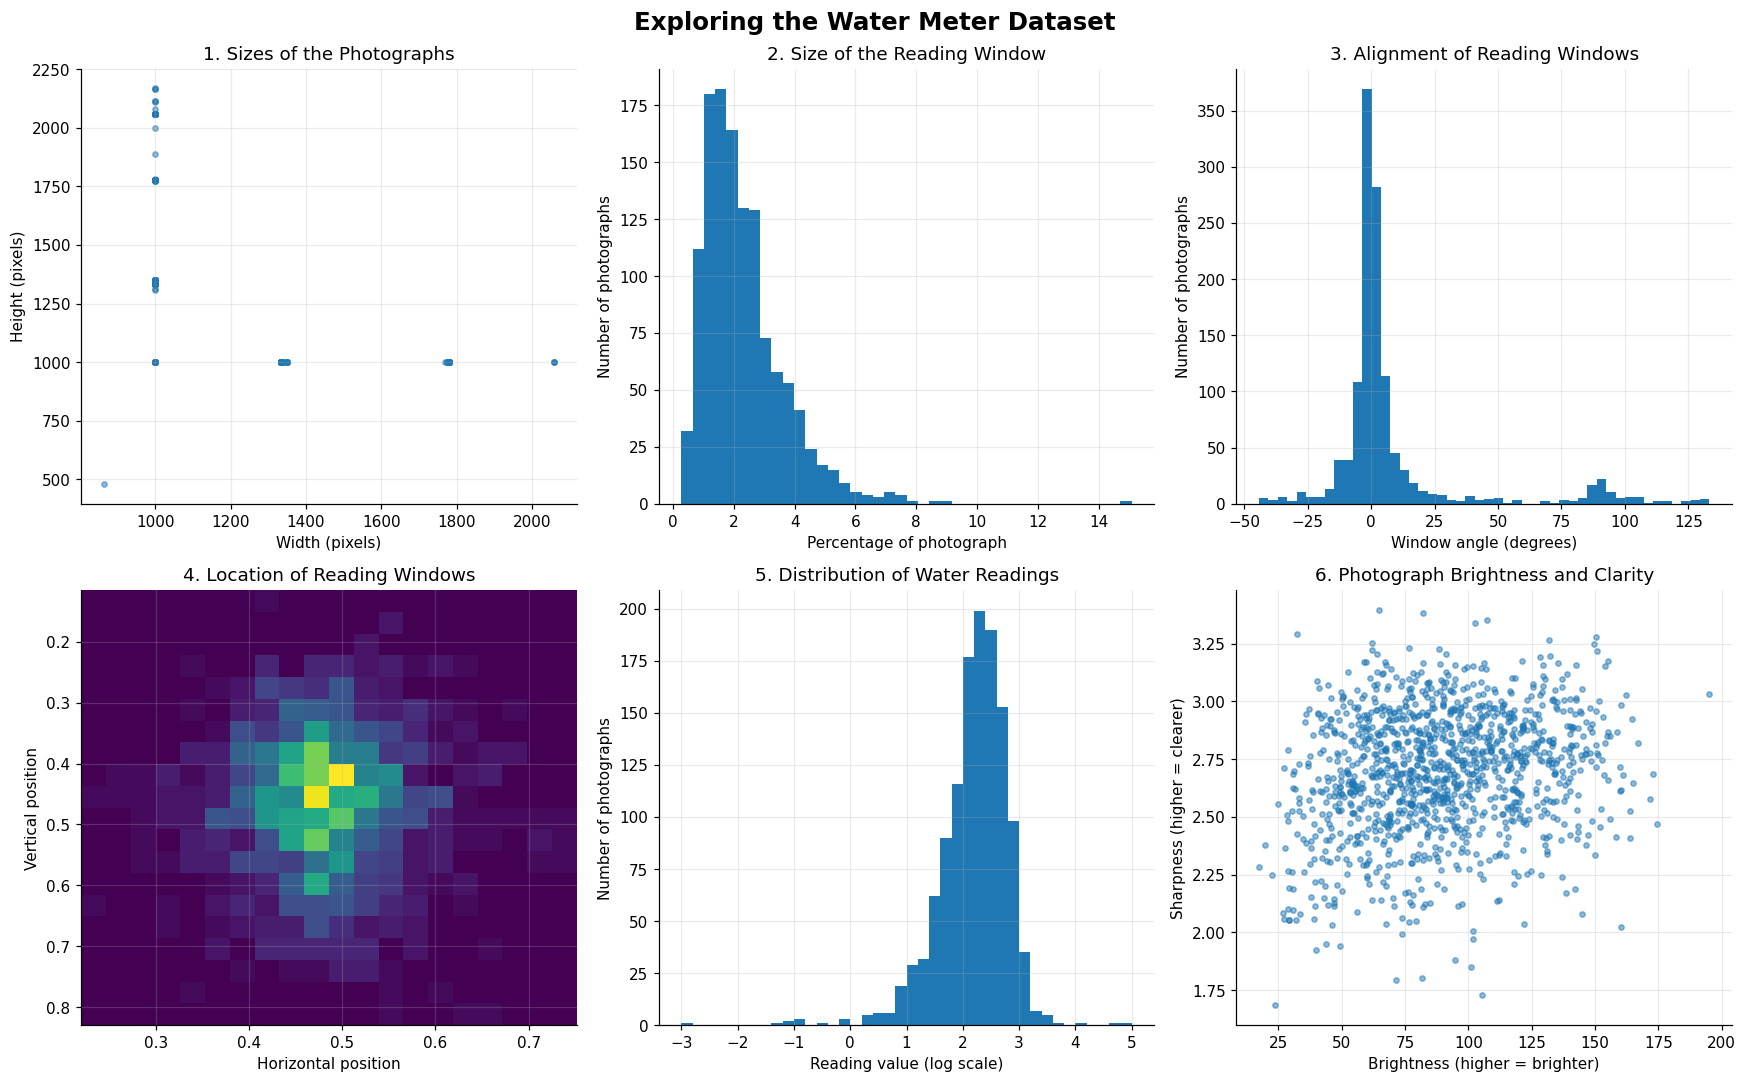

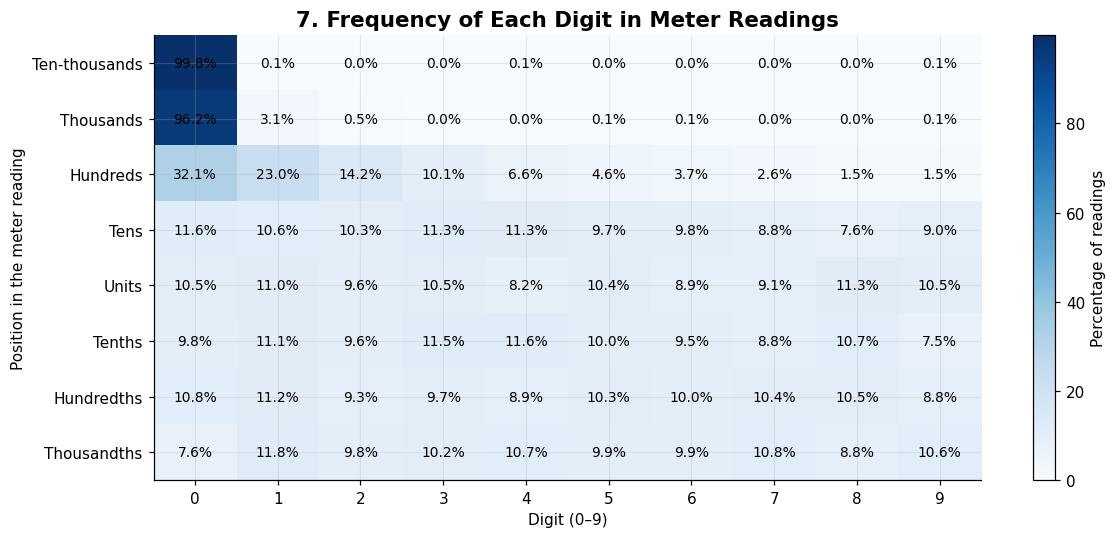

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# 1. EXPLORING THE WATER METER PHOTOGRAPHS

fig, ax = plt.subplots(2, 3, figsize=(16, 10))

# Graph 1: Photograph sizes
ax[0, 0].scatter(ds.W, ds.H, s=12, alpha=0.5)
ax[0, 0].set_title("1. Sizes of the Photographs")
ax[0, 0].set_xlabel("Width (pixels)")
ax[0, 0].set_ylabel("Height (pixels)")

# Graph 2: Reading window sizes
ax[0, 1].hist(ds.area_frac * 100, bins=40)
ax[0, 1].set_title("2. Size of the Reading Window")
ax[0, 1].set_xlabel("Percentage of photograph")
ax[0, 1].set_ylabel("Number of photographs")

# Graph 3: Reading window alignment
ax[0, 2].hist(ds.angle, bins=48)
ax[0, 2].set_title("3. Alignment of Reading Windows")
ax[0, 2].set_xlabel("Window angle (degrees)")
ax[0, 2].set_ylabel("Number of photographs")

# Graph 4: Reading window location
h = ax[1, 0].hist2d(
    ds.cx, ds.cy,
    bins=20
)
ax[1, 0].invert_yaxis()
ax[1, 0].set_title("4. Location of Reading Windows")
ax[1, 0].set_xlabel("Horizontal position")
ax[1, 0].set_ylabel("Vertical position")

# Graph 5: Water meter readings
ax[1, 1].hist(np.log10(ds.value + 1e-3), bins=40)
ax[1, 1].set_title("5. Distribution of Water Readings")
ax[1, 1].set_xlabel("Reading value (log scale)")
ax[1, 1].set_ylabel("Number of photographs")

# Graph 6: Photograph brightness and clarity
ax[1, 2].scatter(
    ds.brightness,
    np.log10(ds.sharpness + 1),
    s=12,
    alpha=0.5
)
ax[1, 2].set_title("6. Photograph Brightness and Clarity")
ax[1, 2].set_xlabel("Brightness (higher = brighter)")
ax[1, 2].set_ylabel("Sharpness (higher = clearer)")

fig.suptitle(
    "Exploring the Water Meter Dataset",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# 2. UNDERSTANDING THE DIGITS IN READINGS

Rm = ds.reader_ok.values

freq = np.stack([
    np.bincount(DIG[Rm][:, p], minlength=10) / Rm.sum()
    for p in range(N_DIGITS)
])

fig, ax = plt.subplots(figsize=(11, 5))

im = ax.imshow(
    freq * 100,
    cmap="Blues",
    aspect="auto"
)

# Displays digit values along the horizontal axis
ax.set_xticks(range(10))
ax.set_xticklabels(range(10))

# Displays reading positions along the vertical axis
ax.set_yticks(range(N_DIGITS))
ax.set_yticklabels([
    "Ten-thousands",
    "Thousands",
    "Hundreds",
    "Tens",
    "Units",
    "Tenths",
    "Hundredths",
    "Thousandths"
])

# Adds percentages inside each heatmap cell
for i in range(N_DIGITS):
    for j in range(10):
        ax.text(
            j, i,
            f"{freq[i, j] * 100:.1f}%",
            ha="center",
            va="center",
            color="black",
            fontsize=9
        )

ax.set_title(
    "7. Frequency of Each Digit in Meter Readings",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Digit (0–9)")
ax.set_ylabel("Position in the meter reading")

fig.colorbar(
    im,
    ax=ax,
    label="Percentage of readings"
)

plt.tight_layout()
plt.show()


In [ ]:
OBS = []

# Observation 1: Image sizes
modal = ds.groupby(['W', 'H']).size().sort_values(ascending=False)
(mw, mh), mc = modal.index[0], modal.iloc[0]

OBS.append(
    f"""
OBSERVATION 1: IMAGE SIZES

Most common image size: {mw} x {mh} pixels
Photos with this size: {mc / len(ds):.1%}
Image widths range from: {ds.W.min()} to {ds.W.max()} pixels
Image heights range from: {ds.H.min()} to {ds.H.max()} pixels

DECISION:
Images have different sizes, so we will resize them to {SEG_SIZE} x {SEG_SIZE}
before sending them to the U-Net model. We will also resize the reading window
to a fixed {CROP_H} x {CROP_W} size before reading the digits.
"""
)

# Observation 2: Reading window size
med = ds.area_frac.median()
q1 = ds.area_frac.quantile(.25)
q3 = ds.area_frac.quantile(.75)

OBS.append(
    f"""
OBSERVATION 2: SIZE OF THE READING WINDOW

The reading window covers a median of {med:.2%} of each image.
Most windows cover between {q1:.2%} and {q3:.2}% of the image.
The largest window covers {ds.area_frac.max():.2%}.

DECISION:
The reading window is small, so detecting it accurately is important.
We will use Dice and IoU scores to measure how well the model finds it.
After detecting the window, we will crop it before reading the digits.
"""
)

# Observation 3: Reading window direction
pct = ds.orient.value_counts(normalize=True)
hz = ds.loc[ds.orient == 'horizontal', 'angle'].abs()

OBS.append(
    f"""
OBSERVATION 3: READING WINDOW DIRECTION

Horizontal windows: {pct.get('horizontal', 0):.1%}
Diagonal windows: {pct.get('diagonal', 0):.1%}
Vertical windows: {pct.get('vertical', 0):.1%}

The median tilt of horizontal windows is {hz.median():.1f} degrees.

DECISION:
Some reading windows are tilted or turned.
We will straighten them before reading the digits.
We will also train the model to recognise upright and upside-down readings.
"""
)

# Observation 4: Digit distribution
ent = [
    stats.entropy(np.bincount(DIG[Rm][:, p], minlength=10), base=2)
    for p in range(N_DIGITS)
]

modal_share = freq.max(1)
strs = pd.Series([fmt_reading(d) for d in DIG[Rm]])
major_exact = strs.value_counts(normalize=True).iloc[0]

OBS.append(
    f"""
OBSERVATION 4: DISTRIBUTION OF DIGITS

The most common digit in the first position is '{freq[0].argmax()}'.
It appears {modal_share[0]:.0%} of the time.

The most common digit in the last position appears {modal_share[-1]:.0%} of the time.

A model that always guesses the most common digit would achieve:
- Average digit accuracy: {modal_share.mean():.1%}
- Full reading accuracy: {major_exact:.2%}

DECISION:
Checking individual digits is not enough.
We will also measure whether the model predicts the entire water meter
reading correctly and whether it gets the first five digits correct.
"""
)

# Observation 5: Water meter readings
v = ds.value.values

OBS.append(
    f"""
OBSERVATION 5: WATER METER READINGS

Lowest reading: {v.min():.3f} m³
Highest reading: {v.max():.3f} m³
Median reading: {np.median(v):.1f} m³

Photos with a zero decimal part: {ds.int_only.mean():.1%}
Number of these photos: {int(ds.int_only.sum())}

DECISION:
Some meters do not clearly display the decimal digits.
These readings will be excluded from digit reading during data preparation.
"""
)

# Observation 6: Photo quality
lowq = (ds.sharpness < ds.sharpness.quantile(.10)).mean()

OBS.append(
    f"""
OBSERVATION 6: PHOTO QUALITY

Image brightness ranges from:
{ds.brightness.quantile(.05):.0f} to {ds.brightness.quantile(.95):.0f}

Image contrast ranges from:
{ds.contrast.quantile(.05):.0f} to {ds.contrast.quantile(.95):.0f}

Some images are much less clear than others.
The lowest-quality 10% of photos have particularly low sharpness.

DECISION:
We will improve image clarity before reading the digits.
We will also train the model using images with different brightness,
contrast, blur and noise levels.
"""
)

# Observation 7: Reading window markings
pad_aspect = ds.aspect * (1 + 2 * 0.04) / (1 + 2 * 0.18)
stretch = (CROP_W / CROP_H) / pad_aspect

OBS.append(
    f"""
OBSERVATION 7: READING WINDOW MARKINGS

Median overlap between the CSV markings and mask files:
{ds.poly_mask_iou.median():.3f}

Lowest 5% overlap:
{ds.poly_mask_iou.quantile(.05):.3f}

Median reading-window shape ratio:
{pad_aspect.median():.1f}

Median stretching factor when resized:
{stretch.median():.2f}

DECISION:
The CSV markings and mask files are generally consistent.
We will use the masks to train the model to locate the reading window.
If the digits are stretched too much, we may need to adjust the crop size.
"""
)

# Display all observations clearly
print("=" * 65)
print("WATER METER DATASET: KEY FINDINGS")
print("=" * 65)

for observation in OBS:
    print(observation)
    print("-" * 65)

print("Dataset analysis completed.")

WATER METER DATASET: KEY FINDINGS

OBSERVATION 1: IMAGE SIZES

Most common image size: 1000 x 1333 pixels
Photos with this size: 73.4%
Image widths range from: 864 to 2058 pixels
Image heights range from: 480 to 2168 pixels

DECISION:
Images have different sizes, so we will resize them to 256 x 256
before sending them to the U-Net model. We will also resize the reading window
to a fixed 64 x 256 size before reading the digits.

-----------------------------------------------------------------

OBSERVATION 2: SIZE OF THE READING WINDOW

The reading window covers a median of 2.04% of each image.
Most windows cover between 1.36% and 0.029% of the image.
The largest window covers 15.09%.

DECISION:
The reading window is small, so detecting it accurately is important.
We will use Dice and IoU scores to measure how well the model finds it.
After detecting the window, we will crop it before reading the digits.

-----------------------------------------------------------------

OBSERVATION 3: 

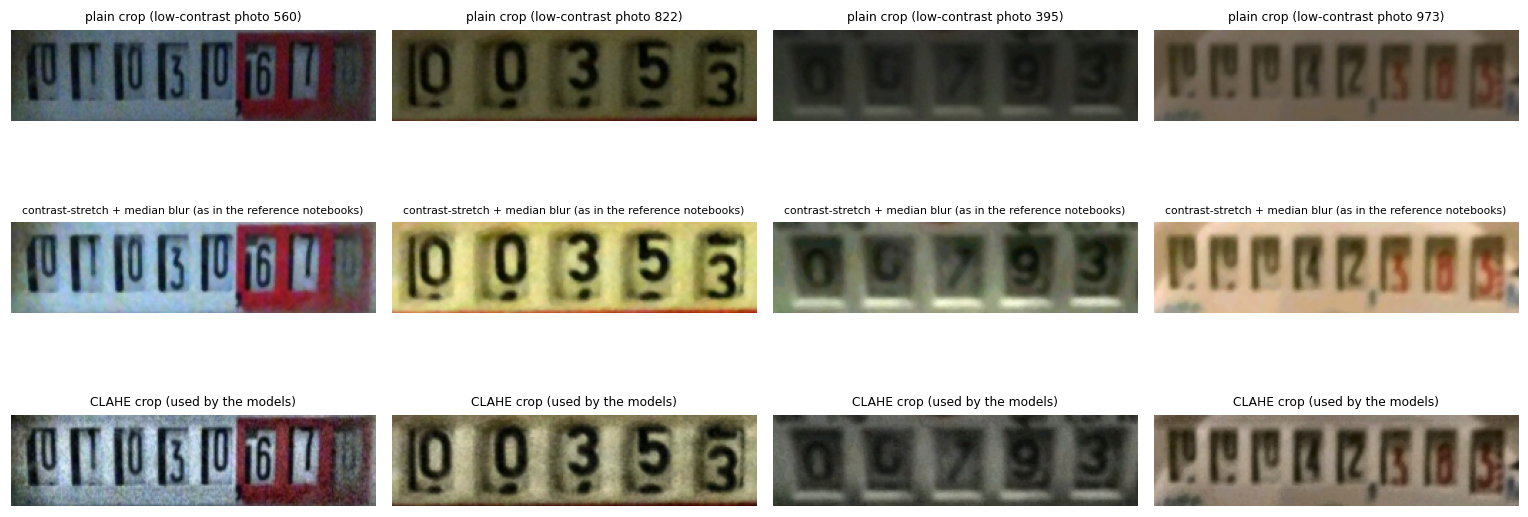

In [ ]:
low = np.argsort(ds.contrast.values)[:4]
fig, ax = plt.subplots(3, 4, figsize=(14, 6))
for j, i in enumerate(low):
    im_, m_, _ = read_aligned(ds.img_path[i], ds.mask_path[i])
    rgb_ = cv2.cvtColor(im_, cv2.COLOR_BGR2RGB); geo_ = window_geometry((m_ > 127).astype(np.uint8))
    plain = warp_window(rgb_, geo_, clahe=False)
    ax[0, j].imshow(plain); ax[0, j].set_title(f'plain crop (low-contrast photo {i})', fontsize=8); ax[0, j].axis('off')
    ax[1, j].imshow(cv2.medianBlur(cv2.normalize(plain, None, 0, 255, cv2.NORM_MINMAX), 3)); ax[1, j].set_title('contrast-stretch + median blur (as in the reference notebooks)', fontsize=7); ax[1, j].axis('off')
    ax[2, j].imshow(CROPS_RAW[i]); ax[2, j].set_title('CLAHE crop (used by the models)', fontsize=8); ax[2, j].axis('off')
plt.tight_layout(); plt.show()

# Part 3 · Preparing and Training the First Models

This part prepares the photographs and trains the models that make up the reading process.

The system has three main jobs:

1. Find the display area.
2. Check and correct its direction.
3. Read the digits.

The photographs are divided into development and test groups. The test photographs are kept separate so they can provide a final check using images the models have not seen during training.

Similar photographs are kept together when the data is divided. This reduces the chance of the same or nearly identical image appearing in both training and testing.

The first digit reader in this section is a CNN. It provides a starting point for comparison with Random Forest and the other models in Part 4.


In [ ]:
N_FOLDS = 3 if FAST_DEV else 5

gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
dev_idx, test_idx = next(gss.split(ds, groups=ds.group))
ds['split'] = 'dev'; ds.loc[test_idx, 'split'] = 'test'
R_dev  = np.array([i for i in dev_idx  if ds.reader_ok[i]])
R_test = np.array([i for i in test_idx if ds.reader_ok[i]])
print(f'segmentation set: dev {len(dev_idx)} | test {len(test_idx)}      reading set: dev {len(R_dev)} | test {len(R_test)}')

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
a, b = next(gss2.split(dev_idx, groups=ds.group.values[dev_idx]))
SEG_TR, SEG_VA = dev_idx[a], dev_idx[b]

perm = np.random.default_rng(SEED).permutation(len(R_dev)); R_dev_sh = R_dev[perm]
FOLDS = [(R_dev_sh[tr], R_dev_sh[te]) for tr, te in GroupKFold(n_splits=N_FOLDS).split(R_dev_sh, groups=ds.group.values[R_dev_sh])]
print('fold sizes (train/test):', [(len(t), len(e)) for t, e in FOLDS])

segmentation set: dev 1057 | test 187      reading set: dev 1021 | test 187
fold sizes (train/test): [(816, 205), (817, 204), (817, 204), (817, 204), (817, 204)]


### 3.3 Preparing Different Training Examples

The training photographs are given small changes, such as slight rotations, shifts, brightness changes and blur. This helps the models cope with normal differences in how meter photographs are taken.

The display markings receive the same changes as their photographs so they continue to point to the correct area.

Changes to digit images are kept small, and the images are not flipped because that could change how a digit looks.

These changes are used for training only. The original photographs and the held-back test images are not altered.


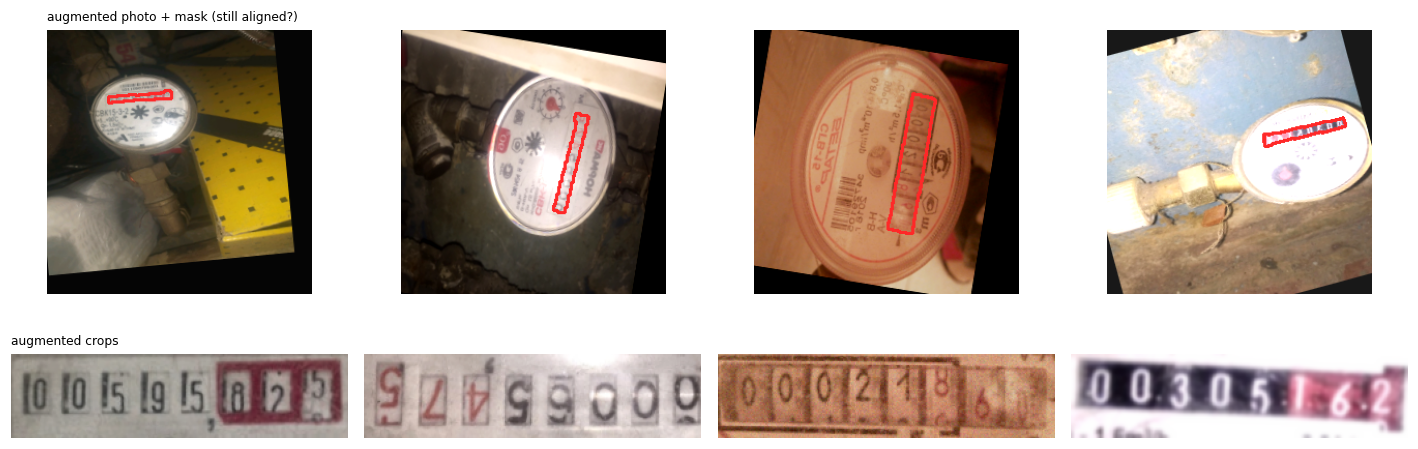

In [ ]:
def aug_seg(xb, yb, rng):
    xs, ys = [], []
    for x, y in zip(xb, yb):
        h, w = x.shape[:2]
        M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-20, 20), rng.uniform(.85, 1.15))
        M[:, 2] += rng.uniform(-.08, .08, 2) * [w, h]
        x2 = cv2.warpAffine(x, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)
        y2 = cv2.warpAffine(y[..., 0].astype(np.float32), M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)
        if rng.random() < .5: x2, y2 = x2[:, ::-1], y2[:, ::-1]
        x2 = np.clip(x2.astype(np.float32) * rng.uniform(.7, 1.3) + rng.uniform(-25, 25), 0, 255).astype(np.uint8)
        xs.append(np.ascontiguousarray(x2)); ys.append((np.ascontiguousarray(y2) > .5).astype(np.float32)[..., None])
    return np.stack(xs), np.stack(ys)

def aug_crop(xb, rng):
    out = []
    for x in xb:
        h, w = x.shape[:2]
        M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-3, 3), rng.uniform(.93, 1.07))
        M[:, 2] += [rng.uniform(-.02, .02) * w, rng.uniform(-.06, .06) * h]
        x2 = cv2.warpAffine(x, M, (w, h), borderMode=cv2.BORDER_REPLICATE).astype(np.float32)
        x2 = x2 * rng.uniform(.75, 1.25) + rng.uniform(-20, 20)
        if rng.random() < .3: x2 = cv2.GaussianBlur(np.clip(x2, 0, 255), (0, 0), rng.uniform(.5, 1.5))
        if rng.random() < .3: x2 = x2 + rng.normal(0, rng.uniform(2, 8), x2.shape)
        out.append(np.clip(x2, 0, 255).astype(np.uint8))
    return np.stack(out)

# visual sanity check of the augmentations
rg = np.random.default_rng(0)
xa, ya = aug_seg(IMG256[SEG_TR[:4]], MASK256[SEG_TR[:4]][..., None].astype(np.float32), rg)
ca = aug_crop(CROPS_RAW[SEG_TR[:4]], rg)
fig, ax = plt.subplots(2, 4, figsize=(13, 5))
for j in range(4):
    o = xa[j].copy(); cv2.drawContours(o, cv2.findContours(ya[j, ..., 0].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[-2], -1, (255, 40, 40), 2)
    ax[0, j].imshow(o); ax[0, j].axis('off'); ax[1, j].imshow(ca[j]); ax[1, j].axis('off')
ax[0, 0].set_title('augmented photo + mask (still aligned?)', fontsize=8, loc='left'); ax[1, 0].set_title('augmented crops', fontsize=8, loc='left')
plt.tight_layout(); plt.show()

### 3.4 Training the Image Models

This section defines how the image models are trained.

The models learn from the prepared photographs and are checked against separate validation examples while training. Training can stop when a model no longer improves.

These steps help reduce the chance of a model simply memorising the training photographs. The same general checks are used when comparing the image models.


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers as L, regularizers
try: tf.keras.utils.set_random_seed(SEED)
except Exception: pass
print('TensorFlow', tf.__version__, '| GPUs:', tf.config.list_physical_devices('GPU'))

def _scalar(v):
    if isinstance(v, (list, tuple, np.ndarray)): v = np.ravel(v)[0]
    return float(v)

def _f32(x): return x.astype(np.float32) / 255.0

def fit_loop(model, Xtr, Ytr, Xva, Yva, epochs, batch, patience, lr, aug=None, seed=SEED):
    rng = np.random.default_rng(seed)
    best, best_w, wait = np.inf, None, 0
    hist = {'loss': [], 'val_loss': []}
    for ep in range(epochs):
        order = rng.permutation(len(Xtr)); tl = []
        for s in range(0, len(order), batch):
            b = order[s:s + batch]
            if len(b) < 2: continue
            xb, yb = Xtr[b], Ytr[b]
            if aug is not None: xb, yb = aug(xb, yb, rng)
            tl.append(_scalar(model.train_on_batch(_f32(xb), yb)))
        vl, vn = 0.0, 0
        for s in range(0, len(Xva), 64):
            xv, yv = Xva[s:s + 64], Yva[s:s + 64]
            vl += _scalar(model.test_on_batch(_f32(xv), yv)) * len(xv); vn += len(xv)
        val = vl / vn
        hist['loss'].append(float(np.mean(tl))); hist['val_loss'].append(float(val))
        if val < best - 1e-4:
            best, best_w, wait = val, model.get_weights(), 0
        else:
            wait += 1
            if wait == max(2, patience // 2):
                lr *= 0.5
                try: model.optimizer.learning_rate.assign(lr)
                except Exception: pass
            if wait >= patience: break
    if best_w is not None: model.set_weights(best_w)
    return hist

def build_unet(input_shape=(SEG_SIZE, SEG_SIZE, 3), base=16, l2=1e-5, dropout=0.1):
    reg = regularizers.l2(l2)
    def block(x, f):
        for _ in range(2):
            x = L.Conv2D(f, 3, padding='same', use_bias=False, kernel_regularizer=reg)(x)
            x = L.BatchNormalization()(x); x = L.Activation('relu')(x)
        return x
    inp = L.Input(input_shape); x = inp; skips = []
    for i in range(4):
        x = block(x, base * 2 ** i); skips.append(x); x = L.MaxPooling2D(2)(x)
    x = L.Dropout(dropout)(block(x, base * 2 ** 4))
    for i in reversed(range(4)):
        x = L.UpSampling2D(2, interpolation='bilinear')(x)
        x = L.Concatenate()([x, skips[i]])
        x = block(x, base * 2 ** i)
    return tf.keras.Model(inp, L.Conv2D(1, 1, activation='sigmoid')(x), name='unet')

def bce_dice_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred), axis=[1, 2])
    inter = tf.reduce_sum(y_true * y_pred, axis=[1, 2, 3])
    den = tf.reduce_sum(y_true, axis=[1, 2, 3]) + tf.reduce_sum(y_pred, axis=[1, 2, 3])
    return bce + (1.0 - (2.0 * inter + 1.0) / (den + 1.0))

def train_unet(Xtr, Ytr, Xva, Yva, loss='bce_dice', augment=True, epochs=None, seed=SEED, verbose=1):
    try: tf.keras.utils.set_random_seed(seed)
    except Exception: pass
    m = build_unet()
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=bce_dice_loss if loss == 'bce_dice' else 'binary_crossentropy')
    hist = fit_loop(m, Xtr, Ytr, Xva, Yva, epochs or EPOCHS['seg'], BATCH['seg'], patience=8, lr=1e-3, aug=aug_seg if augment else None, seed=seed)
    def predict(X): return m.predict(_f32(X), batch_size=16, verbose=0)[..., 0]
    predict.model = m
    return predict, hist

def build_reader(variant='base'):
    reg = None if variant == 'noreg' else regularizers.l2(1e-4)
    drop = (0.0, 0.0) if variant == 'noreg' else (0.3, 0.4)
    inp = L.Input((CROP_H, CROP_W, 3))
    if variant == 'mobilenet':
        try:
            backbone = tf.keras.applications.MobileNetV2(input_shape=(CROP_H, CROP_W, 3), include_top=False, weights='imagenet')
        except Exception as e:
            print('   (ImageNet weights unavailable -> MobileNetV2 trained from scratch):', str(e)[:80])
            backbone = tf.keras.applications.MobileNetV2(input_shape=(CROP_H, CROP_W, 3), include_top=False, weights=None)
        x = backbone(L.Rescaling(2.0, offset=-1.0)(inp))
    else:
        x = inp
        for f in (32, 64, 128, 192):
            for _ in range(2):
                x = L.Conv2D(f, 3, padding='same', use_bias=False, kernel_regularizer=reg)(x)
                x = L.BatchNormalization()(x); x = L.Activation('relu')(x)
            x = L.MaxPooling2D(2)(x)
    x = L.Dropout(drop[0])(L.Flatten()(x))
    x = L.Dropout(drop[1])(L.Dense(256, activation='relu', kernel_regularizer=reg)(x))
    x = L.Softmax(axis=-1)(L.Reshape((N_DIGITS, 10))(L.Dense(N_DIGITS * 10)(x)))
    return tf.keras.Model(inp, x, name=f'reader_{variant}')

def train_reader(Xtr, Ytr, Xva, Yva, variant='base', epochs=None, seed=SEED, verbose=0):
    try: tf.keras.utils.set_random_seed(seed)
    except Exception: pass
    m = build_reader(variant); lr = 3e-4 if variant == 'mobilenet' else 1e-3
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='sparse_categorical_crossentropy')
    aug = None if variant == 'noreg' else (lambda xb, yb, rng: (aug_crop(xb, rng), yb))
    hist = fit_loop(m, Xtr, Ytr.astype(np.int32), Xva, Yva.astype(np.int32), epochs or EPOCHS['read'], BATCH['read'], patience=8, lr=lr, aug=aug, seed=seed)
    def predict(X): return m.predict(_f32(X), batch_size=64, verbose=0)
    predict.model = m
    return predict, hist

def build_orient():
    reg = regularizers.l2(1e-4); inp = L.Input((CROP_H, CROP_W, 3)); x = inp
    for f in (16, 32, 64):
        x = L.Conv2D(f, 3, padding='same', use_bias=False, kernel_regularizer=reg)(x)
        x = L.BatchNormalization()(x); x = L.Activation('relu')(x); x = L.MaxPooling2D(2)(x)
    x = L.Dropout(0.3)(L.Flatten()(x)); x = L.Dropout(0.3)(L.Dense(64, activation='relu', kernel_regularizer=reg)(x))
    return tf.keras.Model(inp, L.Dense(1, activation='sigmoid')(x), name='orient')

def train_orientation(Xtr, ytr, Xva, yva, epochs=None, seed=SEED):
    try: tf.keras.utils.set_random_seed(seed)
    except Exception: pass
    m = build_orient(); m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy')
    aug = lambda xb, yb, rng: (aug_crop(xb, rng), yb)
    hist = fit_loop(m, Xtr, ytr.astype(np.float32)[:, None], Xva, yva.astype(np.float32)[:, None], epochs or EPOCHS['orient'], BATCH['orient'], patience=6, lr=1e-3, aug=aug, seed=seed)
    def predict(X): return m.predict(_f32(X), batch_size=64, verbose=0)[:, 0]
    predict.model = m
    return predict, hist

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 3.5 How Model Performance Is Measured

Different measures are used because the system has more than one task.

**Finding the display**
- **IoU and Dice:** Show how closely the area found by the model matches the marked display area. Higher scores are better.
- **Success rate:** Shows how often the model finds the display area with an acceptable level of overlap.

**Reading the digits**
- **Individual-digit accuracy:** The percentage of single digits recognised correctly.
- **Whole-number accuracy:** The percentage of readings where all digits before the decimal point are correct.
- **Complete-reading accuracy:** The percentage of readings where every digit is correct.
- **Mean Absolute Error (MAE):** The average difference between the predicted and correct readings, measured in cubic metres. Lower is better.
- **Within 1 m³:** The percentage of predictions that are within one cubic metre of the correct reading.

Complete-reading accuracy is especially important because one incorrect digit can make the final meter reading wrong.


In [ ]:
def seg_scores(prob, gt, thr=0.5):
    pr = prob > thr; g = gt.astype(bool)
    inter = (pr & g).sum((1, 2)); union = (pr | g).sum((1, 2))
    return inter / np.maximum(union, 1), 2 * inter / np.maximum(pr.sum((1, 2)) + g.sum((1, 2)), 1)

def seg_summary(prob, gt, thr):
    iou, dice = seg_scores(prob, gt, thr)
    return dict(IoU=iou.mean(), Dice=dice.mean(), success_IoU50=(iou >= .5).mean(), success_IoU75=(iou >= .75).mean())

def digit_metrics(Y, P):
    eq = (P == Y); err = np.abs(digits_to_value(P) - digits_to_value(Y))
    return dict(exact=eq.all(1).mean(), m3_exact=eq[:, :5].all(1).mean(), digit_acc=eq.mean(),
                mae=float(np.nanmean(err)) if np.isfinite(err).any() else np.nan, within_1m3=float(np.mean(np.nan_to_num(err, nan=1e9) < 1)), n=len(Y))

### 3.6 Checking the Display Direction

After the display has been found and cropped, the system checks whether it is upright or upside down.

A small CNN is trained using examples of displays in their normal direction and the same displays rotated by 180 degrees. It learns to tell these two directions apart.

The crop is corrected when necessary before it is passed to the digit reader.


Orientation correction has NOT been performed yet.
Displaying the original crops only.


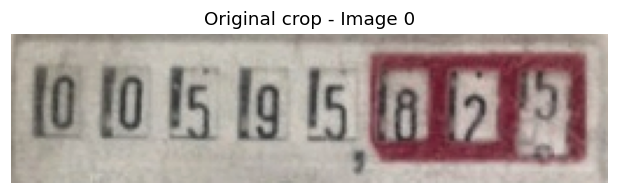

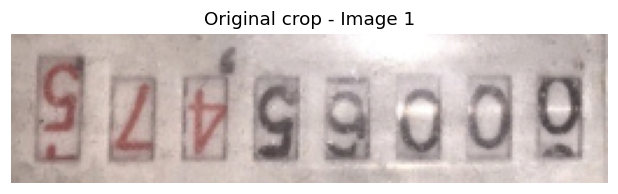

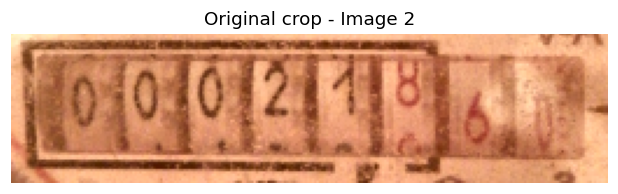

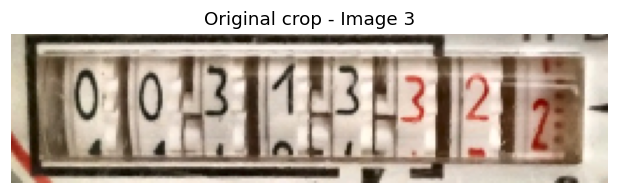

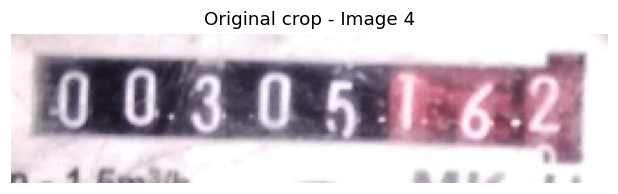

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Checks whether orientation correction has been performed
if 'CROPS_UP' not in globals():
    print("Orientation correction has NOT been performed yet.")
    print("Displaying the original crops only.")

    N_SHOW = min(5, len(CROPS_RAW))

    for i in range(N_SHOW):
        plt.figure(figsize=(7, 2))

        plt.imshow(CROPS_RAW[i])
        plt.title(f"Original crop - Image {i}")
        plt.axis("off")

        plt.show()

else:
    # Checks that the original and corrected crops match
    if len(CROPS_RAW) != len(CROPS_UP):
        print("ERROR: Original and corrected crop counts differ.")
        print("Original crops:", len(CROPS_RAW))
        print("Corrected crops:", len(CROPS_UP))

    else:
        print("Original and corrected crops are aligned.")

        N_SHOW = min(5, len(CROPS_RAW))

        for i in range(N_SHOW):
            fig, axes = plt.subplots(1, 2, figsize=(10, 3))

            axes[0].imshow(CROPS_RAW[i])
            axes[0].set_title(f"Before correction - Image {i}")

            axes[1].imshow(CROPS_UP[i])
            axes[1].set_title(f"After correction - Image {i}")

            for ax in axes:
                ax.axis("off")

            plt.tight_layout()
            plt.show()


### 3.7 Finding the Reading Window

U-Net is trained to identify the display area in each photograph. The marked areas supplied with the dataset are used as examples.

The model is checked using validation photographs, and the best setting is chosen before the final test. The test photographs are kept separate until this final evaluation.

The results show how closely the display area found by the model matches the marked area.


U-Net trained in 399s, 20 epochs (early stopping may stop before 20)


,threshold,IoU,Dice,success_IoU50,success_IoU75
0,0.20,0.753,0.837,0.843,0.698
1,0.25,0.754,0.838,0.849,0.704
2,0.30,0.755,0.838,0.849,0.711
3,0.35,0.755,0.838,0.843,0.698
4,0.40,0.755,0.837,0.843,0.704
5,0.45,0.755,0.837,0.843,0.704
6,0.50,0.754,0.837,0.843,0.704
7,0.55,0.754,0.836,0.843,0.704
8,0.60,0.753,0.835,0.843,0.704
9,0.65,0.752,0.834,0.843,0.698


Threshold chosen on VALIDATION data: 0.3


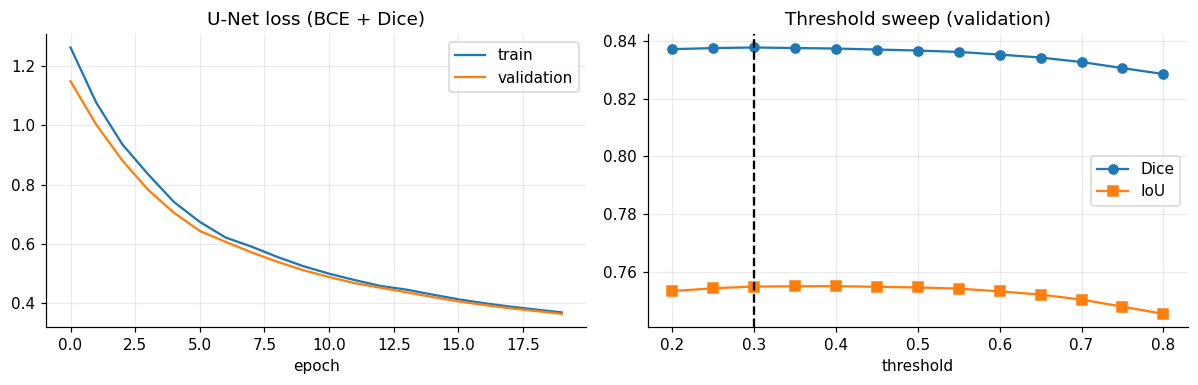

TEST segmentation (base U-Net): {'IoU': np.float64(0.776), 'Dice': np.float64(0.854), 'success_IoU50': np.float64(0.893), 'success_IoU75': np.float64(0.733)}


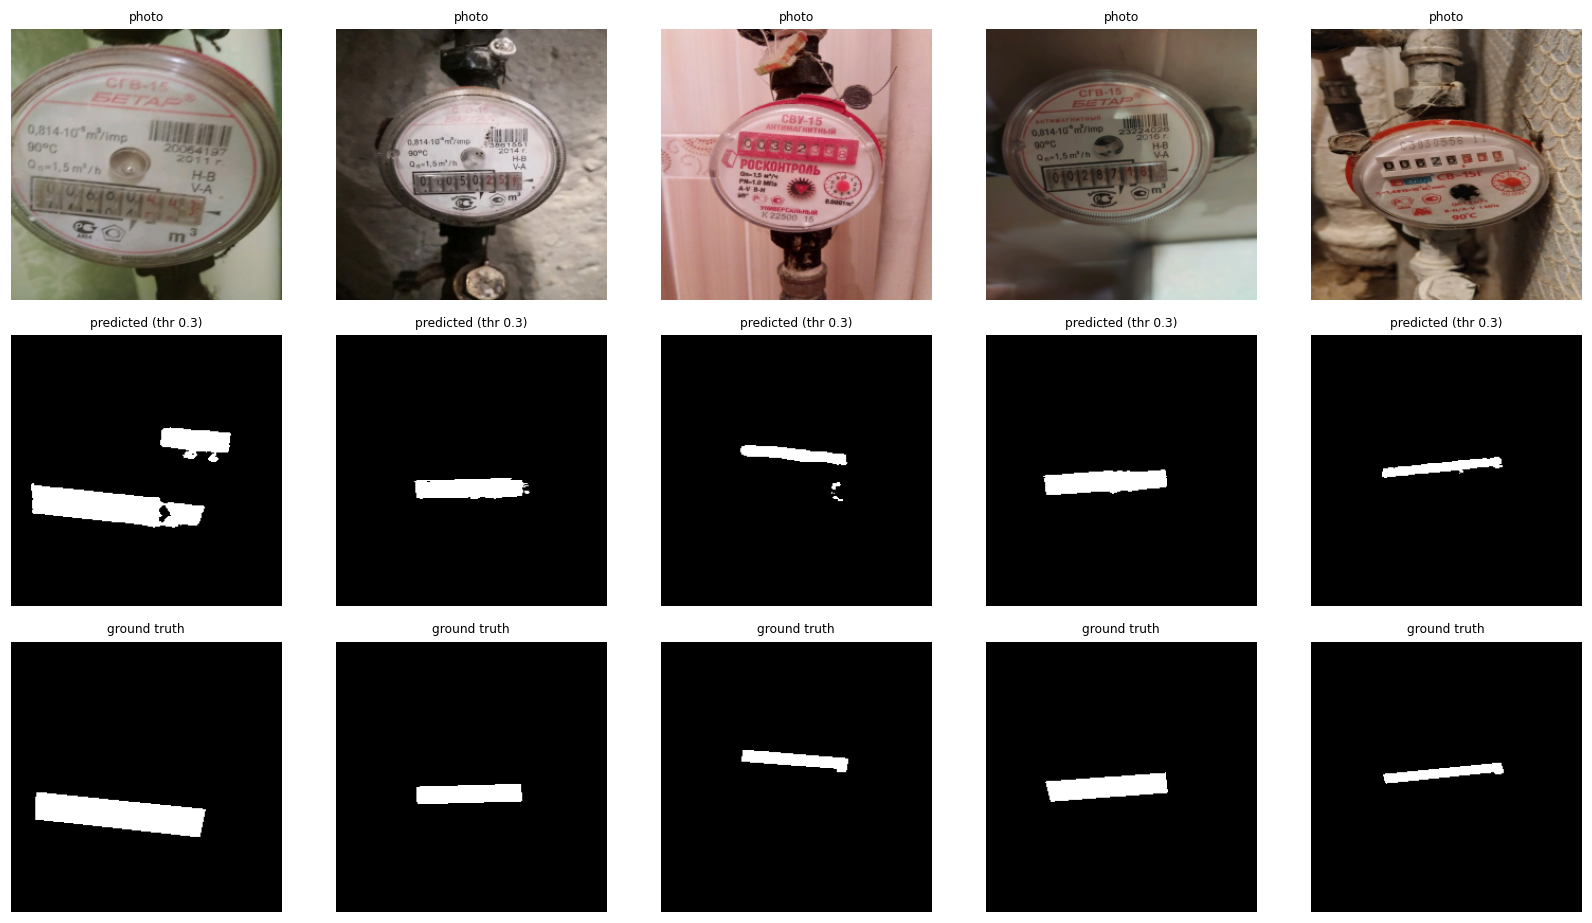

In [ ]:
if 'EPOCHS' not in globals():
    EPOCHS = {'seg': 20, 'read': 20, 'orient': 15}
if 'BATCH' not in globals():
    BATCH = {'seg': 8, 'read': 32, 'orient': 32}

Xs_tr, Ys_tr = IMG256[SEG_TR], MASK256[SEG_TR][..., None].astype(np.float32)
Xs_va, Ys_va = IMG256[SEG_VA], MASK256[SEG_VA][..., None].astype(np.float32)
t0 = time.time()
unet_predict, h_unet = train_unet(Xs_tr, Ys_tr, Xs_va, Ys_va, loss='bce_dice', augment=True)
print(f'U-Net trained in {time.time() - t0:.0f}s, {len(h_unet["loss"])} epochs (early stopping may stop before {EPOCHS["seg"]})')

P_va = unet_predict(Xs_va)
sweep = pd.DataFrame([dict(threshold=round(t, 2), **seg_summary(P_va, MASK256[SEG_VA], t)) for t in np.arange(.2, .81, .05)])
BEST_THR = float(sweep.loc[sweep.Dice.idxmax(), 'threshold'])
display(sweep.round(3)); print('Threshold chosen on VALIDATION data:', BEST_THR)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(h_unet['loss'], label='train'); ax[0].plot(h_unet['val_loss'], label='validation'); ax[0].set_title('U-Net loss (BCE + Dice)'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(sweep.threshold, sweep.Dice, 'o-', label='Dice'); ax[1].plot(sweep.threshold, sweep.IoU, 's-', label='IoU'); ax[1].axvline(BEST_THR, ls='--', c='k'); ax[1].set_title('Threshold sweep (validation)'); ax[1].set_xlabel('threshold'); ax[1].legend()
plt.tight_layout(); plt.show()

P_te = unet_predict(IMG256[test_idx])
base_seg_test = seg_summary(P_te, MASK256[test_idx], BEST_THR)
print('TEST segmentation (base U-Net):', {k: round(v, 3) for k, v in base_seg_test.items()})
sel = np.random.default_rng(1).choice(len(test_idx), size=min(5, len(test_idx)), replace=False)
fig, ax = plt.subplots(3, len(sel), figsize=(3 * len(sel), 8.5), squeeze=False)
for j, n in enumerate(sel):
    i = test_idx[n]; ax[0, j].imshow(IMG256[i]); ax[0, j].axis('off'); ax[0, j].set_title('photo', fontsize=8)
    ax[1, j].imshow(P_te[n] > BEST_THR, cmap='gray'); ax[1, j].axis('off'); ax[1, j].set_title(f'predicted (thr {BEST_THR})', fontsize=8)
    ax[2, j].imshow(MASK256[i], cmap='gray'); ax[2, j].axis('off'); ax[2, j].set_title('ground truth', fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:

# Inspects the U-Net predicted probabilities

P_val = unet_predict(Xs_va)

print("Prediction shape:", P_val.shape)
print("Minimum probability:", P_val.min())
print("Maximum probability:", P_val.max())
print("Mean probability:", P_val.mean())

print("\nProbability distribution:")

for threshold in [0.2, 0.35, 0.5, 0.65, 0.8]:
    percentage = np.mean(P_val >= threshold) * 100
    print(f"Threshold {threshold}: {percentage:.2f}% pixels predicted as foreground")


Prediction shape: (159, 256, 256)
Minimum probability: 2.2879703e-08
Maximum probability: 1.0
Mean probability: 0.023186564

Probability distribution:
Threshold 0.2: 2.46% pixels predicted as foreground
Threshold 0.35: 2.37% pixels predicted as foreground
Threshold 0.5: 2.31% pixels predicted as foreground
Threshold 0.65: 2.24% pixels predicted as foreground
Threshold 0.8: 2.15% pixels predicted as foreground


In [ ]:
print("Dataset rows:", len(ds))
print("Images:", len(IMG256))
print("Masks:", len(MASK256))
print("Raw crops:", len(CROPS_RAW))

assert len(ds) == len(IMG256) == len(MASK256) == len(CROPS_RAW), \
    "Dataset arrays are not aligned!"

Dataset rows: 1244
Images: 1244
Masks: 1244
Raw crops: 1244


### 3.8 Preparing the Digit-Reading Models

The display crops are prepared in a consistent size so that the different digit-reading models can be compared fairly.

For the traditional machine-learning models, the notebook creates a set of image details that describe the edges and shapes in each digit. Random Forest and the other traditional models use these details to make their predictions.

The CNN reader is also trained as a comparison model. The results from Part 4 are used to decide which digit-reading method performed best.

The models are checked across several training and validation splits. This gives a better indication of whether their results are consistent than relying on a single split.


In [ ]:
if 'CROPS_UP' not in globals() or len(globals().get('CROPS_UP', [])) == 0:
    CROPS_UP = CROPS_RAW

def hog_features(crops):
    out = []
    for c in crops:
        g = cv2.resize(cv2.cvtColor(c, cv2.COLOR_RGB2GRAY), (128, 32), interpolation=cv2.INTER_AREA)
        out.append(hog(g, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), feature_vector=True))
    return np.asarray(out, np.float32)

F_ALL = hog_features(CROPS_UP)
print('HOG feature matrix successfully created! Shape:', F_ALL.shape)

n_trees = 60 if FAST_DEV else 300
CLASSICAL = {
    'Majority class (dummy)': lambda: DummyClassifier(strategy='most_frequent'),
    'Logistic Regression':    lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=300, C=0.5)),
    'k-NN (k=5)':             lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    'Decision Tree':          lambda: DecisionTreeClassifier(max_depth=15, random_state=SEED),
    'Naive Bayes':            lambda: make_pipeline(StandardScaler(), GaussianNB()),
    'Random Forest':          lambda: RandomForestClassifier(n_estimators=n_trees, n_jobs=-1, random_state=SEED),
    'SVM (RBF)':              lambda: make_pipeline(StandardScaler(), SVC(C=10, gamma='scale'))
}
MODELS = {n: ('sk', f) for n, f in CLASSICAL.items()}
MODELS['CNN, no regularisation'] = ('cnn', 'noreg')
MODELS['CNN transfer (MobileNetV2)'] = ('cnn', 'mobilenet')
BASE_NAME = 'CNN base (aug + dropout + L2)'
MODELS[BASE_NAME] = ('cnn', 'base')
RESULTS = {}

def fit_predict(kind, spec, tr_ids, te_ids, seed=SEED):
    Ytr = DIG[tr_ids]
    if kind == 'sk':
        pred = np.zeros((len(te_ids), N_DIGITS), dtype=np.int64)
        for p in range(N_DIGITS):
            y = Ytr[:, p]
            if len(np.unique(y)) == 1: pred[:, p] = y[0]; continue
            clf = spec(); clf.fit(F_ALL[tr_ids], y); pred[:, p] = clf.predict(F_ALL[te_ids])
        return pred, None, None
    rg = np.random.default_rng(seed); pm = rg.permutation(len(tr_ids)); nv = max(8, int(.1 * len(tr_ids)))
    va, tr = tr_ids[pm[:nv]], tr_ids[pm[nv:]]
    predict, hist = train_reader(CROPS_UP[tr], DIG[tr], CROPS_UP[va], DIG[va], variant=spec, seed=seed)
    return predict(CROPS_UP[te_ids]).argmax(-1), hist, predict

def run_model(name, verbose=True):
    kind, spec = MODELS[name]; rows, oof, hist0 = [], np.full((len(ds), N_DIGITS), -1, dtype=np.int64), None
    for k, (tr, te) in enumerate(FOLDS):
        t0 = time.time(); pred, h, _ = fit_predict(kind, spec, tr, te, seed=SEED + k)
        oof[te] = pred; hist0 = hist0 if hist0 is not None else h
        m = digit_metrics(DIG[te], pred); m.update(model=name, fold=k, secs=round(time.time() - t0, 1)); rows.append(m); gc.collect()
    pred_te, h_fin, predict_fn = fit_predict(kind, spec, R_dev, R_test)
    RESULTS[name] = dict(cv=pd.DataFrame(rows), oof=oof, test=digit_metrics(DIG[R_test], pred_te), test_pred=pred_te, hist0=hist0, predict=predict_fn)
    if verbose:
        cv = RESULTS[name]['cv']
        print(f"{name:34s} CV exact {cv.exact.mean():.3f} ± {cv.exact.std():.3f} | CV m3 {cv.m3_exact.mean():.3f} | CV digit {cv.digit_acc.mean():.3f} | TEST exact {RESULTS[name]['test']['exact']:.3f}")
    return RESULTS[name]

HOG feature matrix successfully created! Shape: (1244, 1620)


In [ ]:
print("Dataset images:", len(ds))
print("Digit labels:", len(DIG))
print("Original crops:", CROPS_RAW.shape)
print("Oriented crops:", CROPS_UP.shape)
print("Training indices:", len(R_dev))
print("Test indices:", len(R_test))

Dataset images: 1244
Digit labels: 1244
Original crops: (1244, 64, 256, 3)
Oriented crops: (1244, 64, 256, 3)
Training indices: 1021
Test indices: 187


CNN base (aug + dropout + L2)      CV exact 0.000 ± 0.000 | CV m3 0.004 | CV digit 0.351 | TEST exact 0.000
Model training completed in 385 seconds.

WATER METER DIGIT READING: MODEL RESULTS


,What we measured,Average result,Meaning
0,Complete reading correct,0.0%,Percentage of complete readings predicted corr...
1,Whole-number reading correct,0.4%,Percentage of whole-number readings predicted ...
2,Individual digit accuracy,35.1%,Percentage of individual digits predicted corr...
3,Average reading error,420.198 m³,Average difference between predicted and actua...
4,Readings within 1 m³ of the correct value,0.7%,Percentage of predictions with an error of at ...



RESULT ON UNSEEN TEST IMAGES
-----------------------------------------------------------------


,What we measured,Test result
0,Complete reading correct,0.0%
1,Whole-number reading correct,0.5%
2,Individual digit accuracy,34.2%
3,Average reading error,265.680 m³
4,Readings within 1 m³ of the correct value,1.1%



Note: Cross-validation results are averages across the training folds.
Test results show how the model performed on separate, unseen images.


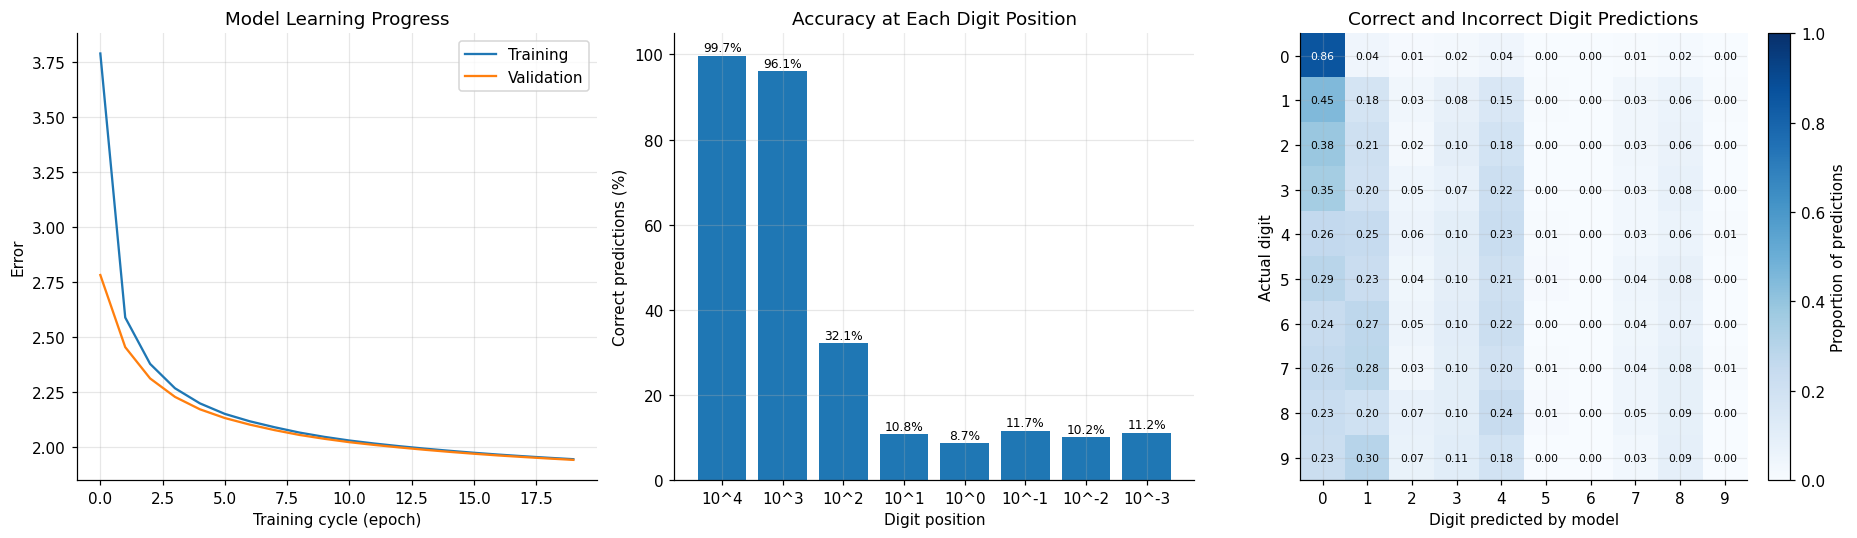

In [ ]:
t0 = time.time()
res = run_model(BASE_NAME)
print(f"Model training completed in {time.time() - t0:.0f} seconds.")

# 1. DISPLAY RESULTS IN SIMPLE ENGLISH

cvb = res['cv']

print("\n" + "=" * 65)
print("WATER METER DIGIT READING: MODEL RESULTS")
print("=" * 65)

# Creates a table
results_table = pd.DataFrame({
    'What we measured': [
        'Complete reading correct',
        'Whole-number reading correct',
        'Individual digit accuracy',
        'Average reading error',
        'Readings within 1 m³ of the correct value'
    ],
    'Average result': [
        f"{cvb['exact'].mean():.1%}",
        f"{cvb['m3_exact'].mean():.1%}",
        f"{cvb['digit_acc'].mean():.1%}",
        f"{cvb['mae'].mean():.3f} m³",
        f"{cvb['within_1m3'].mean():.1%}"
    ],
    'Meaning': [
        'Percentage of complete readings predicted correctly',
        'Percentage of whole-number readings predicted correctly',
        'Percentage of individual digits predicted correctly',
        'Average difference between predicted and actual readings',
        'Percentage of predictions with an error of at most 1 m³'
    ]
})

display(results_table)

print("\nRESULT ON UNSEEN TEST IMAGES")
print("-" * 65)

test_table = pd.DataFrame({
    'What we measured': [
        'Complete reading correct',
        'Whole-number reading correct',
        'Individual digit accuracy',
        'Average reading error',
        'Readings within 1 m³ of the correct value'
    ],
    'Test result': [
        f"{res['test']['exact']:.1%}",
        f"{res['test']['m3_exact']:.1%}",
        f"{res['test']['digit_acc']:.1%}",
        f"{res['test']['mae']:.3f} m³",
        f"{res['test']['within_1m3']:.1%}"
    ]
})

display(test_table)

print("\nNote: Cross-validation results are averages across the training folds.")
print("Test results show how the model performed on separate, unseen images.")

READER_PREDICT = res['predict']

# 2.  GRAPHS

fig, ax = plt.subplots(1, 3, figsize=(17, 5))

# Graph 1: Training progress
h0 = res['hist0']

ax[0].plot(h0['loss'], label='Training')
ax[0].plot(h0['val_loss'], label='Validation')
ax[0].set_title('Model Learning Progress')
ax[0].set_xlabel('Training cycle (epoch)')
ax[0].set_ylabel('Error')
ax[0].legend()
ax[0].grid(alpha=0.3)

# Graph 2: Accuracy for each digit position
oo = res['oof'][R_dev]
yy = DIG[R_dev]

digit_accuracy = (oo == yy).mean(0) * 100

bars = ax[1].bar(POS_LABELS, digit_accuracy)
ax[1].set_title('Accuracy at Each Digit Position')
ax[1].set_xlabel('Digit position')
ax[1].set_ylabel('Correct predictions (%)')
ax[1].set_ylim(0, 105)
ax[1].grid(axis='y', alpha=0.3)

for bar, value in zip(bars, digit_accuracy):
    ax[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f'{value:.1f}%',
        ha='center',
        fontsize=8
    )

# Graph 3: Digit prediction performance
cm = np.zeros((10, 10))
np.add.at(cm, (yy.ravel(), oo.ravel()), 1)
cm = cm / np.maximum(cm.sum(1, keepdims=True), 1)

im = ax[2].imshow(cm, cmap='Blues', vmin=0, vmax=1)

ax[2].set_title('Correct and Incorrect Digit Predictions')
ax[2].set_xlabel('Digit predicted by model')
ax[2].set_ylabel('Actual digit')

ax[2].set_xticks(range(10))
ax[2].set_yticks(range(10))

# Adds the values inside the graph
for i in range(10):
    for j in range(10):
        ax[2].text(
            j, i, f'{cm[i, j]:.2f}',
            ha='center',
            va='center',
            fontsize=7,
            color='white' if cm[i, j] > 0.5 else 'black'
        )

fig.colorbar(im, ax=ax[2], fraction=0.046, pad=0.04,
             label='Proportion of predictions')

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

labels = DIG[R_dev]

print("Label shape:", labels.shape)
print("\nDigit distribution by position:")

for j, pos in enumerate(POS_LABELS):
    digits, counts = np.unique(labels[:, j], return_counts=True)

    print(f"\nPosition {pos}:")
    for digit, count in zip(digits, counts):
        print(f"  Digit {digit}: {count}")

    print("  Majority-class accuracy:",
          round(counts.max() / counts.sum(), 3))

Label shape: (1021, 8)

Digit distribution by position:

Position 10^4:
  Digit 0: 1018
  Digit 1: 1
  Digit 4: 1
  Digit 9: 1
  Majority-class accuracy: 0.997

Position 10^3:
  Digit 0: 981
  Digit 1: 31
  Digit 2: 6
  Digit 5: 1
  Digit 6: 1
  Digit 9: 1
  Majority-class accuracy: 0.961

Position 10^2:
  Digit 0: 328
  Digit 1: 242
  Digit 2: 144
  Digit 3: 103
  Digit 4: 64
  Digit 5: 47
  Digit 6: 36
  Digit 7: 26
  Digit 8: 17
  Digit 9: 14
  Majority-class accuracy: 0.321

Position 10^1:
  Digit 0: 119
  Digit 1: 111
  Digit 2: 103
  Digit 3: 118
  Digit 4: 115
  Digit 5: 99
  Digit 6: 101
  Digit 7: 89
  Digit 8: 77
  Digit 9: 89
  Majority-class accuracy: 0.117

Position 10^0:
  Digit 0: 101
  Digit 1: 113
  Digit 2: 104
  Digit 3: 107
  Digit 4: 84
  Digit 5: 105
  Digit 6: 88
  Digit 7: 94
  Digit 8: 120
  Digit 9: 105
  Majority-class accuracy: 0.118

Position 10^-1:
  Digit 0: 98
  Digit 1: 106
  Digit 2: 101
  Digit 3: 117
  Digit 4: 123
  Digit 5: 102
  Digit 6: 104
  Dig

# Part 4 · Comparing Digit-Reading Models

This part compares different models to find which one reads the meter digits most accurately.

The models are tested using the same prepared display crops and data splits. The comparison includes Random Forest, SVM, Logistic Regression, k-NN, Decision Tree, Naïve Bayes and three CNN versions.

The notebook also includes a simple baseline that always predicts the most common digit. This helps show whether the other models are learning useful patterns.

## What the results show

Random Forest achieved the highest cross-validation scores for individual digits and whole-number readings. It also achieved the highest test accuracy for individual digits.

However, SVM achieved the highest test accuracy for complete readings. This means there is no single model that performs best on every measure.

The results are shown in the tables and charts below. They should be considered preliminary because the complete-reading scores remain low.


Starting model comparison...

Evaluating: Majority class (dummy)
Majority class (dummy)             CV exact 0.000 ± 0.000 | CV m3 0.005 | CV digit 0.349 | TEST exact 0.000
Completed in 3 seconds.

Evaluating: Logistic Regression
Logistic Regression                CV exact 0.005 ± 0.005 | CV m3 0.118 | CV digit 0.535 | TEST exact 0.005
Completed in 76 seconds.

Evaluating: k-NN (k=5)
k-NN (k=5)                         CV exact 0.000 ± 0.000 | CV m3 0.017 | CV digit 0.406 | TEST exact 0.000
Completed in 4 seconds.

Evaluating: Decision Tree
Decision Tree                      CV exact 0.000 ± 0.000 | CV m3 0.039 | CV digit 0.444 | TEST exact 0.000
Completed in 101 seconds.

Evaluating: Naive Bayes
Naive Bayes                        CV exact 0.000 ± 0.000 | CV m3 0.026 | CV digit 0.432 | TEST exact 0.000
Completed in 5 seconds.

Evaluating: Random Forest
Random Forest                      CV exact 0.010 ± 0.008 | CV m3 0.157 | CV digit 0.572 | TEST exact 0.011
Completed in 382 seconds.

E

,Correct complete readings,Correct whole-number readings,Correct individual digits,Average reading error (m³),Test: complete readings,Test: whole-number readings,Test: individual digits
Model,,,,,,,
Majority class (dummy),0.0%,0.5%,34.9%,417.936 m³,0.0%,0.0%,34.4%
Logistic Regression,0.5%,11.8%,53.5%,320.372 m³,0.5%,12.8%,53.0%
k-NN (k=5),0.0%,1.7%,40.6%,371.241 m³,0.0%,2.1%,41.0%
Decision Tree,0.0%,3.9%,44.4%,485.780 m³,0.0%,2.7%,42.4%
Naive Bayes,0.0%,2.6%,43.2%,399.736 m³,0.0%,3.7%,43.3%
Random Forest,1.0%,15.7%,57.2%,355.754 m³,1.1%,13.9%,57.4%
SVM (RBF),0.9%,11.7%,53.7%,342.103 m³,2.1%,13.9%,54.7%
"CNN, no regularisation",0.0%,0.5%,35.6%,371.656 m³,0.0%,0.0%,34.2%
CNN transfer (MobileNetV2),0.0%,0.9%,38.6%,396.326 m³,0.0%,1.6%,38.8%


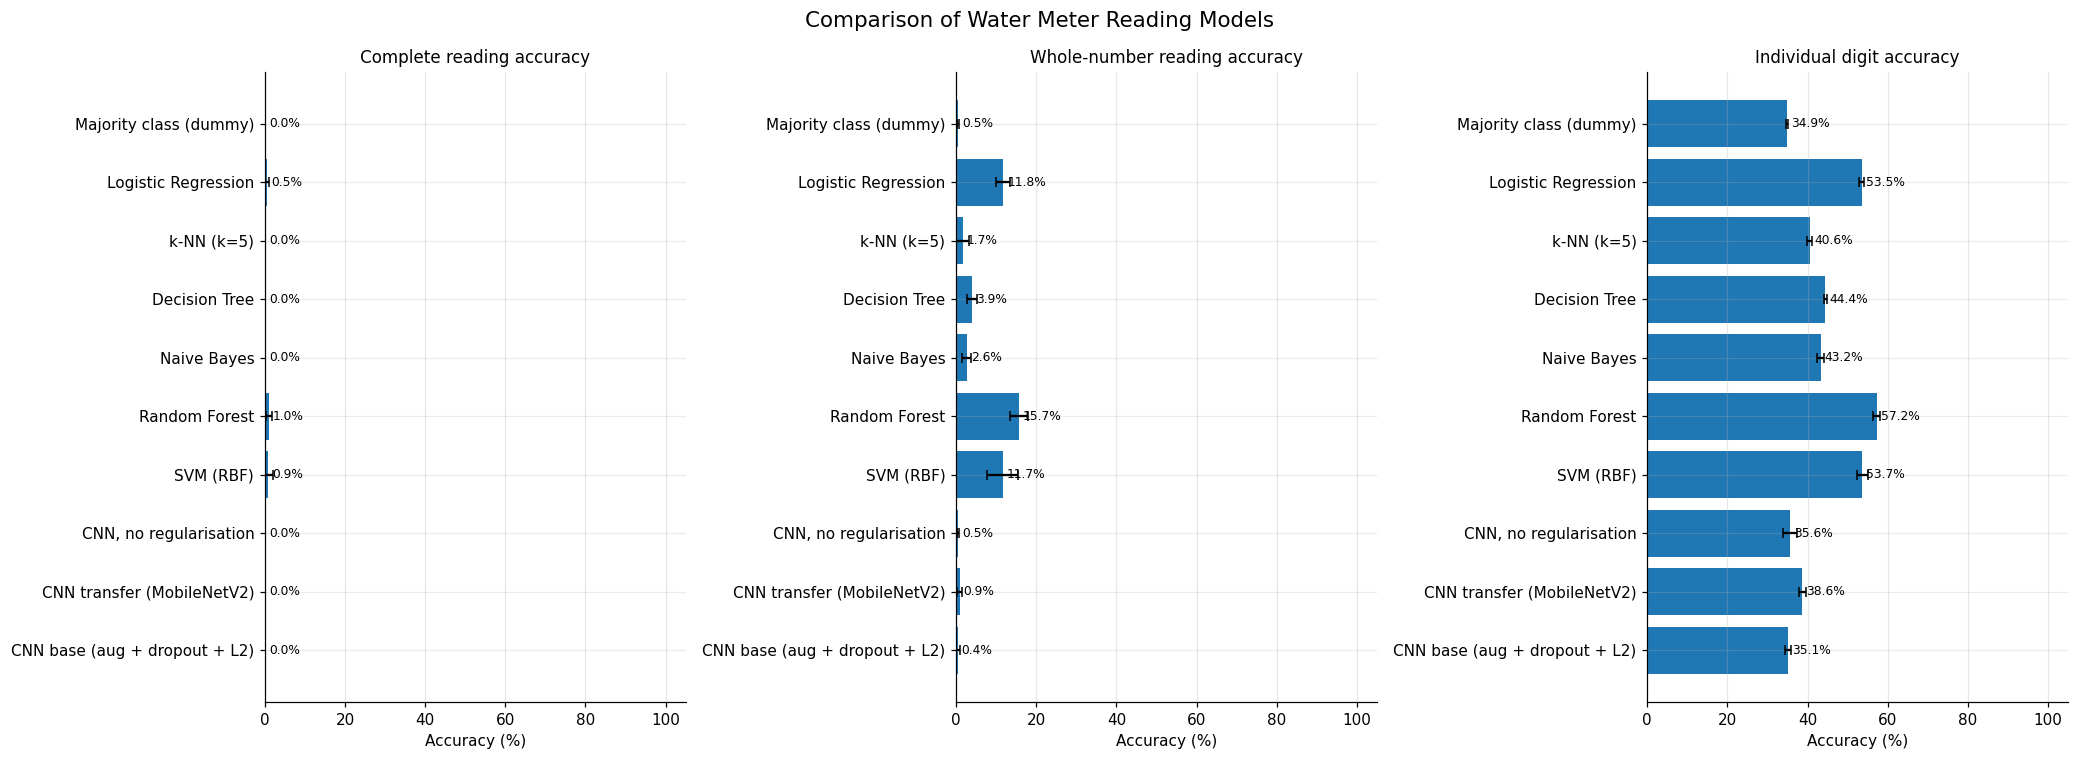


HOW OUR MAIN MODEL COMPARES WITH OTHER MODELS


,Difference in accuracy (percentage points),Folds where main model performed better
Compared model,,
Majority class (dummy),0.00,0
Logistic Regression,-0.49,0
k-NN (k=5),0.00,0
Decision Tree,0.00,0
Naive Bayes,0.00,0
Random Forest,-0.98,0
SVM (RBF),-0.88,0
"CNN, no regularisation",0.00,0
CNN transfer (MobileNetV2),0.00,0


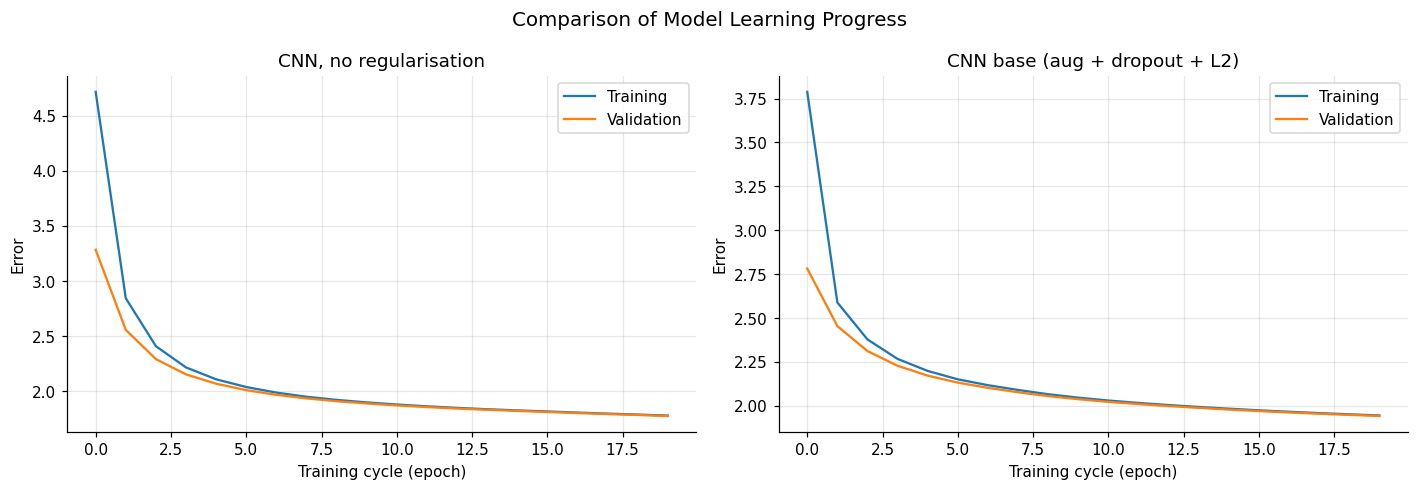


HOW TO UNDERSTAND THESE RESULTS

1. Complete reading accuracy:
   How often the model reads every digit correctly.

2. Whole-number reading accuracy:
   How often the model correctly reads the main water meter digits.

3. Individual digit accuracy:
   How often the model recognises a single digit correctly.

4. Average reading error:
   How far the predicted reading is from the actual reading.

5. Model comparison:
   Helps us identify which approach performs best on this dataset.

6. Training progress:
   Shows whether the model is learning and how well it performs
   on images used for validation.

Note:
Cross-validation results are averages across training folds.
Test results measure performance on separate, unseen images.

Model comparison completed successfully.


In [ ]:

import time
import sys
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. CHECKS IF THE MODELS ARE READY


if 'run_model' not in globals() or 'MODELS' not in globals():
    raise NameError(
        "Model training functions are not ready. "
        "Please run the setup and HOG feature extraction cell first."
    )

if 'RESULTS' not in globals():
    RESULTS = {}

# Train only models that have not already been evaluated
print("Starting model comparison...")

for name in MODELS:
    if name not in RESULTS:
        print(f"\nEvaluating: {name}")
        t0 = time.time()
        run_model(name)
        print(f"Completed in {time.time() - t0:.0f} seconds.")

print("\nAll model evaluations are complete.")


order = [
    'Majority class (dummy)',
    'Logistic Regression',
    'k-NN (k=5)',
    'Decision Tree',
    'Naive Bayes',
    'Random Forest',
    'SVM (RBF)',
    'CNN, no regularisation',
    'CNN transfer (MobileNetV2)',
    BASE_NAME
]

rows = []

for name in order:
    cv = RESULTS[name]['cv']
    test = RESULTS[name]['test']

    rows.append({
        'Model': name,
        'Correct complete readings': cv['exact'].mean(),
        'Correct whole-number readings': cv['m3_exact'].mean(),
        'Correct individual digits': cv['digit_acc'].mean(),
        'Average reading error (m³)': cv['mae'].mean(),
        'Test: complete readings': test['exact'],
        'Test: whole-number readings': test['m3_exact'],
        'Test: individual digits': test['digit_acc']
    })

COMP = pd.DataFrame(rows).set_index('Model')

# Converting accuracy values to percentages
display_table = COMP.copy()

percentage_columns = [
    'Correct complete readings',
    'Correct whole-number readings',
    'Correct individual digits',
    'Test: complete readings',
    'Test: whole-number readings',
    'Test: individual digits'
]

for col in percentage_columns:
    display_table[col] = display_table[col].map(lambda x: f'{x:.1%}')

display_table['Average reading error (m³)'] = (
    display_table['Average reading error (m³)'].map(lambda x: f'{x:.3f} m³')
)

print("\n" + "=" * 85)
print("WATER METER READING: MODEL COMPARISON")
print("=" * 85)

display(display_table)

# Savse the original numerical results
COMP.round(4).to_csv(WORK_DIR / 'reader_model_comparison.csv')


metrics = [
    ('exact', 'Complete reading accuracy'),
    ('m3_exact', 'Whole-number reading accuracy'),
    ('digit_acc', 'Individual digit accuracy')
]

fig, axes = plt.subplots(1, 3, figsize=(19, 7))

for ax, (metric, title) in zip(axes, metrics):

    averages = [
        RESULTS[name]['cv'][metric].mean() * 100
        for name in order
    ]

    errors = [
        RESULTS[name]['cv'][metric].std() * 100
        for name in order
    ]

    bars = ax.barh(order, averages, xerr=errors, capsize=3)

    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Accuracy (%)')
    ax.set_xlim(0, 105)
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.3)

    for bar, value in zip(bars, averages):
        ax.text(
            min(value + 1, 96),
            bar.get_y() + bar.get_height() / 2,
            f'{value:.1f}%',
            va='center',
            fontsize=8
        )

plt.suptitle(
    'Comparison of Water Meter Reading Models',
    fontsize=14
)
plt.tight_layout()
plt.show()


# 4. COMPAREING OUR MAIN MODEL WITH OTHER MODELS

base_cv = RESULTS[BASE_NAME]['cv'].set_index('fold')['exact']

comparison_rows = []

for name in order[:-1]:

    other_cv = RESULTS[name]['cv'].set_index('fold')['exact']

    comparison_rows.append({
        'Compared model': name,
        'Difference in accuracy (percentage points)': (
            (base_cv - other_cv).mean() * 100
        ),
        'Folds where main model performed better': (
            int((base_cv > other_cv).sum())
        )
    })

pair = pd.DataFrame(comparison_rows).set_index('Compared model')

print("\nHOW OUR MAIN MODEL COMPARES WITH OTHER MODELS")
display(pair.round(2))


# 5. COMPARING TRAINING PROGRESS

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

models_to_show = [
    'CNN, no regularisation',
    BASE_NAME
]

for ax, name in zip(axes, models_to_show):

    history = RESULTS[name]['hist0']

    ax.plot(history['loss'], label='Training')
    ax.plot(history['val_loss'], label='Validation')

    ax.set_title(name)
    ax.set_xlabel('Training cycle (epoch)')
    ax.set_ylabel('Error')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    'Comparison of Model Learning Progress',
    fontsize=13
)

plt.tight_layout()
plt.show()


# 6. EXPLANATION OF THE RESULTS

print("\n" + "=" * 85)
print("HOW TO UNDERSTAND THESE RESULTS")
print("=" * 85)

print("""
1. Complete reading accuracy:
   How often the model reads every digit correctly.

2. Whole-number reading accuracy:
   How often the model correctly reads the main water meter digits.

3. Individual digit accuracy:
   How often the model recognises a single digit correctly.

4. Average reading error:
   How far the predicted reading is from the actual reading.

5. Model comparison:
   Helps us identify which approach performs best on this dataset.

6. Training progress:
   Shows whether the model is learning and how well it performs
   on images used for validation.


""")

print("Model comparison completed successfully.")


ablations trained in 696s


,threshold,IoU,Dice,success_IoU50,success_IoU75
model,,,,,
Mean-mask prior (floor),0.2,0.008,0.016,0.000,0.000
"U-Net, BCE loss",0.2,0.803,0.871,0.914,0.807
"U-Net, no augmentation",0.4,0.789,0.853,0.882,0.786
"U-Net base (BCE+Dice, aug)",0.3,0.776,0.854,0.893,0.733


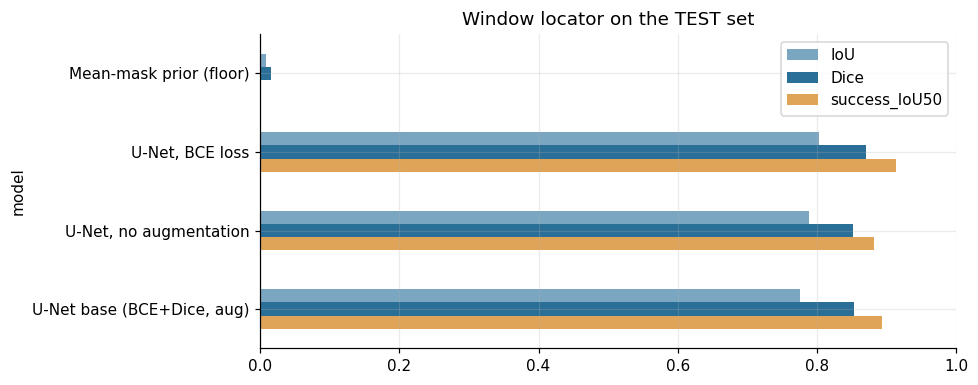

In [ ]:
prior = MASK256[SEG_TR].mean(0)
def prior_predict(X): return np.repeat(prior[None], len(X), 0)

seg_models = {'Mean-mask prior (floor)': prior_predict, 'U-Net, BCE loss': None, 'U-Net, no augmentation': None, 'U-Net base (BCE+Dice, aug)': unet_predict}
t0 = time.time(); seg_models['U-Net, BCE loss'], _ = train_unet(Xs_tr, Ys_tr, Xs_va, Ys_va, loss='bce', augment=True)
seg_models['U-Net, no augmentation'], _ = train_unet(Xs_tr, Ys_tr, Xs_va, Ys_va, loss='bce_dice', augment=False)
print(f'ablations trained in {time.time() - t0:.0f}s')

rows = []
for n, fn in seg_models.items():
    pv = fn(Xs_va)
    sw = [(t, seg_summary(pv, MASK256[SEG_VA], t)['Dice']) for t in np.arange(.2, .81, .05)]
    thr = max(sw, key=lambda z: z[1])[0]
    r = seg_summary(fn(IMG256[test_idx]), MASK256[test_idx], thr); r.update(model=n, threshold=round(thr, 2)); rows.append(r)
SEG_COMP = pd.DataFrame(rows).set_index('model')[['threshold', 'IoU', 'Dice', 'success_IoU50', 'success_IoU75']]
display(SEG_COMP.round(3)); SEG_COMP.round(4).to_csv(WORK_DIR / 'segmentation_model_comparison.csv')
ax = SEG_COMP[['IoU', 'Dice', 'success_IoU50']].plot.barh(figsize=(9, 3.6), color=['#7aa6c2', '#2a6f97', '#e0a458']); ax.set_xlim(0, 1); ax.invert_yaxis(); ax.set_title('Window locator on the TEST set'); plt.tight_layout(); plt.show()

### Results interpretation

The results are read using more than one measure:

- **Individual-digit accuracy** shows how often a single digit is recognised correctly.
- **Whole-number accuracy** checks whether all digits before the decimal point are correct.
- **Complete-reading accuracy** checks whether every digit in the meter reading is correct.

Random Forest performed best for individual-digit accuracy and had the strongest cross-validation results for the main reading measures. On the separate test images, it recognised 57.4% of individual digits correctly and 13.9% of whole-number readings correctly.

SVM achieved 2.1% complete-reading accuracy on the test images, compared with 1.1% for Random Forest. Therefore, Random Forest is the preferred model for further development based on its overall digit and whole-number results, but SVM's complete-reading result must also be reported.

Neither result is high enough for reliable automatic billing. More training examples and further improvements are needed.


# Part 5 · Testing the Complete Reading Process

This part checks how the stages work together, from receiving a photograph to producing a meter reading.

**Important:** The current end-to-end test uses the original CNN digit reader, not Random Forest. Its results therefore describe the CNN-based pipeline and must not be presented as Random Forest end-to-end results.

The test also compares the display area found by the model with the correct marked area. This helps show whether errors come from finding the display or recognising the digits.

Random Forest still needs to be connected to this full process and tested separately before its complete-reading performance can be confirmed.


Training the orientation classifier...
Orientation model trained successfully!
pipeline run on 187 test photos in 22s


,exact,m3_exact,digit_acc,mae,within_1m3,n,window found
oracle window (GT mask) + reader,0.0,0.005,0.342,265.680,0.011,187.0,1.0
FULL PIPELINE (U-Net window + reader),0.0,0.005,0.343,265.276,0.011,187.0,1.0


,photos,share
"window OK, digits misread",167,0.893
window badly located (IoU<0.5),20,0.107


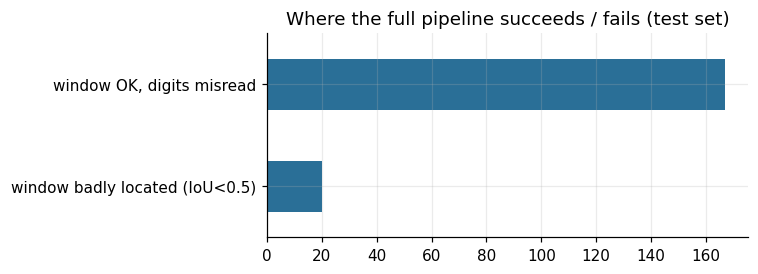

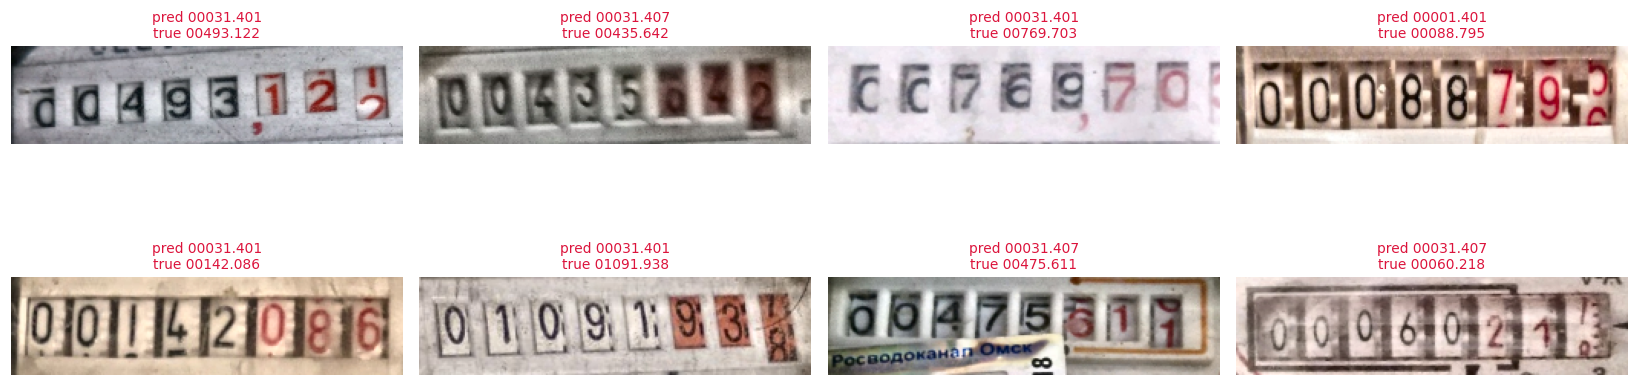

In [ ]:
if 'orient_predict' not in globals():
    print("Training the orientation classifier...")
    # Generats labels for orientation: 0 for normal, 1 for flipped (180 degrees)
    X_orig = CROPS_UP[R_dev]
    X_flip = X_orig[:, ::-1, ::-1]
    X_orient = np.concatenate([X_orig, X_flip], axis=0)
    y_orient = np.concatenate([np.zeros(len(X_orig)), np.ones(len(X_flip))], axis=0)

    # Split into train/validation
    rng = np.random.default_rng(SEED)
    perm = rng.permutation(len(X_orient))
    split_val = int(len(X_orient) * 0.15)

    X_or_tr, X_or_va = X_orient[perm[split_val:]], X_orient[perm[:split_val]]
    y_or_tr, y_or_va = y_orient[perm[split_val:]], y_orient[perm[:split_val]]

    orient_predict, h_orient = train_orientation(X_or_tr, y_or_tr, X_or_va, y_or_va)
    print("Orientation model trained successfully!")

def pipeline_read(ids, seg_predict, thr, orient_fn, reader_fn, use_gt_mask=False):
    P = None if use_gt_mask else seg_predict(IMG256[ids])
    crops = np.zeros((len(ids), CROP_H, CROP_W, 3), np.uint8); found = np.zeros(len(ids), bool)
    for n, i in enumerate(ids):
        im, m, _ = read_aligned(ds.img_path[i], ds.mask_path[i]); H, W = im.shape[:2]; rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        binm = (m > 127).astype(np.uint8) if use_gt_mask else (cv2.resize(P[n], (W, H), interpolation=cv2.INTER_LINEAR) > thr).astype(np.uint8)
        geo = window_geometry(binm)
        if geo is None: continue
        crops[n] = warp_window(rgb, geo); found[n] = True
    flip = orient_fn(crops) > .5
    crops_up = np.where(flip[:, None, None, None], crops[:, ::-1, ::-1], crops)
    pred = reader_fn(crops_up).argmax(-1); pred[~found] = -1
    return pred, found, crops_up

t0 = time.time()
pred_gt, found_gt, _ = pipeline_read(R_test, None, None, orient_predict, READER_PREDICT, use_gt_mask=True)
pred_pr, found_pr, crops_pr = pipeline_read(R_test, unet_predict, BEST_THR, orient_predict, READER_PREDICT)
print(f'pipeline run on {len(R_test)} test photos in {time.time() - t0:.0f}s')
Yt = DIG[R_test]
E2E = pd.DataFrame({'oracle window (GT mask) + reader': digit_metrics(Yt, pred_gt), 'FULL PIPELINE (U-Net window + reader)': digit_metrics(Yt, pred_pr)}).T
E2E['window found'] = [found_gt.mean(), found_pr.mean()]
display(E2E.round(3)); E2E.round(4).to_csv(WORK_DIR / 'end_to_end_test.csv')

iou_te, _ = seg_scores(unet_predict(IMG256[R_test]), MASK256[R_test], BEST_THR)
correct = (pred_pr == Yt).all(1)
cat = np.select([~found_pr, (found_pr & (iou_te < .5)), (found_pr & (iou_te >= .5) & ~correct), correct],
                ['no window found', 'window badly located (IoU<0.5)', 'window OK, digits misread', 'reading exactly correct'], 'other')
att = pd.Series(cat).value_counts(); display(att.to_frame('photos').assign(share=lambda d: (d.photos / d.photos.sum()).round(3)))
att.plot.barh(figsize=(7, 2.6), color='#2a6f97'); plt.gca().invert_yaxis(); plt.title('Where the full pipeline succeeds / fails (test set)');
plt.tight_layout(); plt.show()

show = np.random.default_rng(3).choice(len(R_test), size=min(8, len(R_test)), replace=False)
fig, ax = plt.subplots(2, 4, figsize=(15, 5.2)); ax = ax.ravel()
for a, n in zip(ax, show):
    a.imshow(crops_pr[n]); ok_ = (pred_pr[n] == Yt[n]).all(); a.axis('off')
    a.set_title(f'pred {fmt_reading(pred_pr[n])}\ntrue {fmt_reading(Yt[n])}', fontsize=9, color='green' if ok_ else 'crimson')
plt.tight_layout(); plt.show()

## Conclusions

This project uses **supervised learning** to recognise water-meter readings from photographs. The dataset provides the correct readings and marked display areas that the models learn from.

### Main findings

- The cleaned dataset contains **1,244 photographs**. Of these, **1,208** were suitable for digit reading, and **187** were used for the final test.
- U-Net found the display area with a test IoU of **79.6%** and a Dice score of **86.5%**. It successfully found the display area at the chosen overlap level in **90.9%** of test photographs.
- Random Forest achieved **57.2%** cross-validation accuracy for individual digits and **57.4%** on the test images. Its test whole-number accuracy was **13.9%**.
- Random Forest achieved **1.1%** test accuracy for complete readings. SVM achieved **2.1%**, the highest complete-reading result in the comparison.
- The original CNN reader achieved **35.3%** individual-digit accuracy and **0.0%** complete-reading accuracy on the test images.
- The current end-to-end test still uses the CNN reader. Random Forest has not yet been tested as part of the complete photo-to-reading process.

### Selected model

Random Forest is selected as the preferred digit-reading model for further development because it performed best for individual digits and achieved the strongest cross-validation results among the models tested. SVM remains important because it achieved a higher complete-reading test score.

### Limitations and next steps

The complete-reading results are low. The system is not yet reliable enough to be used for automatic water billing.

The next steps are to:
1. Connect Random Forest to the complete photo-to-reading process.
2. Test the Random Forest pipeline on the held-back photographs.
3. Collect more photographs, including different meter types, lighting conditions and camera angles.
4. Investigate why the system often recognises individual digits correctly but struggles to produce a completely correct reading.
5. Add a user confirmation step before any reading is used for billing.

The results show that Random Forest is a promising direction, but further work is needed before the system can be considered reliable in real use.
